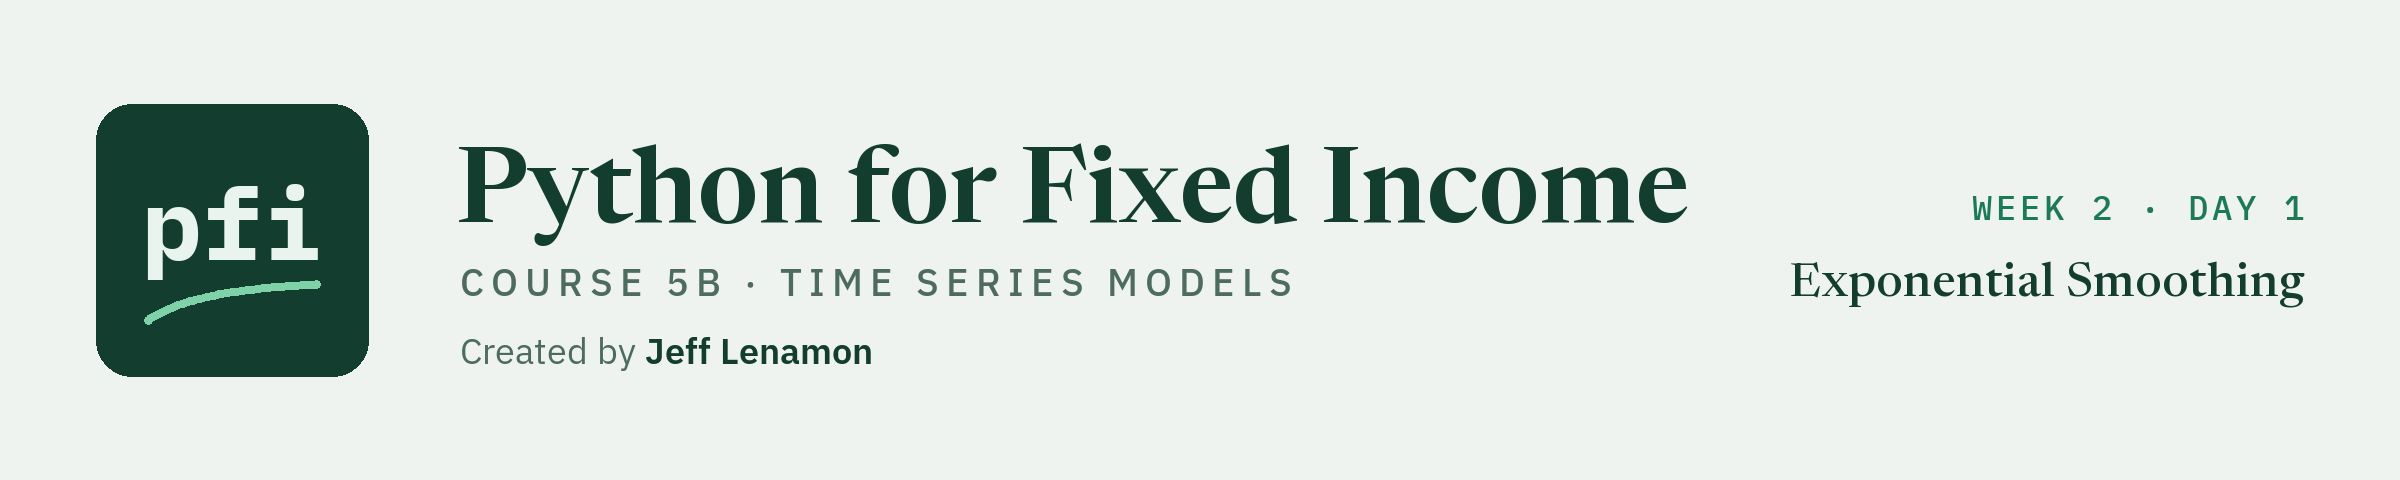

# Exponential Smoothing

Week 2, Day 1. Smooth the Treasury curve with an exponentially weighted average, read every setting of the smoothing model, and score it walk-forward against carrying the last value forward.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course3_synthetic_spreads.csv`, 2,940 daily investment grade and high yield spreads in bp, one per date of the Treasury file: **synthetic**, invented for Course 3, not ICE, Moody's, or any index.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course5b_time_series/week2/day1/06_exponential_smoothing.ipynb)

Week 1 ended on a plain finding: nothing fitted to the 10 Yr's own past beat carrying the last value forward. Week 2 starts with the oldest and simplest family of models for a series, **exponential smoothing**: an average that weights the newest row most and lets older rows fade. It is two things at once. As a description it is a smooth line through a noisy level, and the same recursion with squared changes is a measure of volatility. As a rule it gives each date a one-step value, which can be scored.

* **The task is in the past tense.** A smoothing gives a "one-step value" for a date from the rows dated before it. Every fit is on earlier dates only, every score is on dates inside 2015-01-02 to 2022-12-30, and nothing is fitted for or reported at a later date. The held-out years stay closed until the capstone.
* **A model's output is a fitted change**: the smoothing's one-step value less the last value. The rule it is judged against is **the last value carried forward**, which is day 2's baseline, with day 2's numbers on day 2's five folds.
* **Smoothing is scored on levels**, as day 2 scored the baselines, so the last value scores exactly day 2's table. Day 5's AR(1), scored on changes, sits in the same table: the miss in a change and the miss in a level are the same number.
* **The honest question** is whether a smoother can be closer to the next level than the last value is. Alpha equal to 1 *is* the last value, so the question is whether least squares ever moves away from 1.

Today you will:

1. Build an EWMA by hand, as one recursive formula, and sweep alpha in panels.
2. Fit simple smoothing by least squares and see that it is the EWMA with the best alpha.
3. Add Holt's linear trend and a damped trend, and read what each adds.
4. Read every setting of `ExponentialSmoothing`, and sweep the ones that matter.
5. Score the smoothers walk-forward (`walk_forward_smoothing`) against the last value, the drift, and day 5's AR(1).
6. Use the EWMA of squared changes as a volatility description, which leads to day 7.

Q. Set up today's work folder: the thread settings, the seed, the data files, and the modules.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course5b_time_series/requirements.txt
NEEDED = {
    "arch": "arch==8.0.0",
    "catboost": "catboost==1.2.10",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "optuna": "optuna==5.0.0",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

18 packages checked, all present


In [2]:
# today's setup: the thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These two lines must run before numpy, pandas, statsmodels, arch, or LightGBM is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("statsmodels", "statsmodels"), ("arch", "arch"), ("scipy", "scipy"), ("sklearn", "scikit-learn"), ("lightgbm", "lightgbm"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course5b_time_series/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scipy": "1.18.1", "statsmodels": "0.15.0", "arch": "8.0.0", "scikit-learn": "1.9.1", "lightgbm": "4.7.0", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course5b_06_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["treasury_par_yields.csv", "course3_synthetic_spreads.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scipy 1.18.1, statsmodels 0.15.0, arch 8.0.0, scikit-learn 1.9.1, lightgbm 4.7.0, matplotlib 3.11.2, pytest 9.1.1
Work folder: pfi_course5b_06_wdcj4fj3, in your temp folder
Data files from the data folder of the course repo: treasury_par_yields.csv, course3_synthetic_spreads.csv
SEED = 42


The setup cell is the same in every Course 5B notebook. `mlkit.py`, `tskit.py`, and its tests below are the files as day 5 left them, and `plotkit.py` is the series' chart helpers, unchanged. Today appends four functions to `tskit.py`.

Q. Write `mlkit.py`, Course 4's complete module, unchanged. `tskit` imports it.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


Q. Write `tskit.py` and `test_tskit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile tskit.py
"""tskit: the time series pieces of Course 5B, written down and tested.

Written day by day in Python for Fixed Income, Course 5B: Time Series Models.

Conventions, the same in every function:
- A series is a pandas Series, and a frame a DataFrame, indexed by date: unique and ascending.
- Yields are in percent and changes in bp, as in the Treasury file; each docstring states its unit.
- A function that describes or repairs data never fills an earlier date from a later one unless its docstring
  says so in its first lines.
- A fitted value is for a date inside the file, from a model fitted on earlier dates only; it is never a
  statement about a date after the file ends.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # dated tables

import mlkit  # Course 4's module: its walk-forward splits and its past-only check are used from day 2


def _check_dated(index: pd.Index, name: str) -> None:
    """Stop unless the index is a DatetimeIndex that is not empty, unique, and ascending."""
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{name} must be indexed by date (a DatetimeIndex)")
    if len(index) == 0:
        raise ValueError(f"{name} is empty")
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError(f"{name} must have unique dates in ascending order")


def gap_report(frame: pd.DataFrame) -> pd.DataFrame:
    """One row per column of a dated frame: where the series starts and ends, and where its values are blank.

    Input: frame, dated rows (a DatetimeIndex, unique and ascending), one column per series.
    Output: a DataFrame indexed by column name, with
      rows: the rows in the frame;
      first_valid, last_valid: the first and last dates that hold a value (NaT for a column with none);
      before_start: blank rows before first_valid (a series that had not started yet);
      blank_inside: blank cells from first_valid to last_valid (outages and gaps inside the series);
      after_end: blank rows after last_valid;
      longest_inside: the longest run of consecutive blank rows inside the series (0 when there is none).
    A date with no row at all (a market holiday) is not in the frame, so it is not counted here: compare the
    index with a calendar to find those.
    Raises ValueError for an empty frame or an index that is not dated, unique, and ascending.
    """
    _check_dated(frame.index, "frame")
    rows = []
    for column in frame.columns:
        blank = frame[column].isna().to_numpy()
        first, last = frame[column].first_valid_index(), frame[column].last_valid_index()
        if first is None:
            # no value at all: every row counts as before the start
            rows.append({"column": column, "rows": len(blank), "first_valid": pd.NaT, "last_valid": pd.NaT,
                         "before_start": len(blank), "blank_inside": 0, "after_end": 0, "longest_inside": 0})
            continue
        start, end = frame.index.get_loc(first), frame.index.get_loc(last)
        inside = blank[start:end + 1]
        runs = gap_runs(frame[column].iloc[start:end + 1]) if inside.any() else None
        rows.append({"column": column, "rows": len(blank), "first_valid": first, "last_valid": last,
                     "before_start": start, "blank_inside": int(inside.sum()), "after_end": len(blank) - 1 - end,
                     "longest_inside": int(runs["rows"].max()) if runs is not None else 0})
    return pd.DataFrame(rows).set_index("column")


def gap_runs(series: pd.Series) -> pd.DataFrame:
    """Every run of consecutive blank values in a dated series: its first and last dates and its length in rows.

    Input: series, values indexed by date (unique and ascending).
    Output: a DataFrame with one row per run, in date order, and columns
      start, end: the first and last dates of the run;
      rows: the number of blank rows in the run;
      kind: "before start" for a run on the first row (the series had not started), "after end" for a run that
      reaches the last row, and "inside" for every other run.
    With nothing blank, an empty DataFrame with the same columns. A run counts rows, not calendar days: a blank
    Friday and the blank Monday after it are one run of 2 rows.
    Raises ValueError for an empty series or an index that is not dated, unique, and ascending.
    """
    _check_dated(series.index, "series")
    blank = series.isna()
    # a new run number starts wherever blank switches between True and False
    run_number = (blank != blank.shift(fill_value=not blank.iloc[0])).cumsum()
    runs = []
    for _, run in series[blank].groupby(run_number[blank]):
        first, last = series.index.get_loc(run.index[0]), series.index.get_loc(run.index[-1])
        kind = "before start" if first == 0 else "after end" if last == len(series) - 1 else "inside"
        runs.append({"start": run.index[0], "end": run.index[-1], "rows": len(run), "kind": kind})
    return pd.DataFrame(runs, columns=["start", "end", "rows", "kind"])


def apply_corrections(frame: pd.DataFrame, corrections: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply a table of corrections to a dated frame; return the corrected copy and a log of every change.

    Inputs: frame, dated rows, one column per series; corrections, a DataFrame with the columns date, column,
    value, source: one row per cell to set. value may be NaN, to blank a value known to be wrong (DataFrame.update
    skips a NaN, so it can never blank a cell).
    Output: (corrected, log). corrected is a copy of frame; the input is not changed. log is a DataFrame with the
    columns date, column, old, new, source: one row per cell whose value changed, in the order of corrections.
    A correction that leaves a cell as it was (the same number, or blank to blank) is not a change and is not
    logged.
    Raises ValueError if corrections lacks one of its four columns, if a date or a column is not in frame, or if
    one cell is corrected twice.
    """
    _check_dated(frame.index, "frame")
    needed = ["date", "column", "value", "source"]
    missing = [name for name in needed if name not in corrections.columns]
    if missing:
        raise ValueError(f"corrections needs the columns {needed}; missing {missing}")
    dates = pd.DatetimeIndex(corrections["date"])
    unknown_dates = dates[~dates.isin(frame.index)]
    if len(unknown_dates):
        raise ValueError(f"dates not in frame: {[str(d.date()) for d in unknown_dates]}")
    unknown_columns = sorted(set(corrections["column"]) - set(frame.columns))
    if unknown_columns:
        raise ValueError(f"columns not in frame: {unknown_columns}")
    cells = list(zip(dates, corrections["column"]))
    if len(set(cells)) != len(cells):
        raise ValueError("a cell is corrected twice: one row per cell")
    corrected = frame.copy()
    log = []
    for (date, column), value, source in zip(cells, corrections["value"], corrections["source"]):
        old = corrected.at[date, column]
        # blank to blank, or the same number, is not a change
        if (pd.isna(old) and pd.isna(value)) or old == value:
            continue
        corrected.at[date, column] = value
        log.append({"date": date, "column": column, "old": old, "new": value, "source": source})
    return corrected, pd.DataFrame(log, columns=["date", "column", "old", "new", "source"])


NAIVE_KINDS = ("last", "mean", "drift")


def naive_values(series: pd.Series, kind: str, n_train: int | None = None) -> pd.Series:
    """The naive value for each date, built only from the dates before it.

    Input: series, a dated Series of levels (yields or spreads in bp); kind, one of
      "last": the value on the row before (the last value carried forward);
      "mean": the average of the values so far;
      "drift": the last value plus the average change so far;
    n_train, the rows of the training window, or None.
    Output: with n_train None, a Series on every date of the input, NaN where no earlier date exists (the first row
    for "last" and "mean", the first two rows for "drift"), each value using the dates before it. With n_train set,
    the Series for the dates from row n_train on, where "mean" and "drift" use the average level and the average
    change of the first n_train rows only, fixed for the whole test window, and "last" still uses the row before.
    Raises ValueError for an unknown kind, an input that is not dated and ascending, or an n_train outside 2 to
    one less than the rows.
    """
    _check_dated(series.index, "series")
    if kind not in NAIVE_KINDS:
        raise ValueError(f"kind must be one of {NAIVE_KINDS}, not {kind!r}")
    last = series.shift(1)
    if n_train is None:
        # expanding averages, shifted one row so a date never sees itself
        mean = series.expanding().mean().shift(1)
        change = series.diff().expanding().mean().shift(1)
        return {"last": last, "mean": mean, "drift": last + change}[kind]
    if not 2 <= n_train < len(series):
        raise ValueError(f"n_train must be from 2 to {len(series) - 1}, not {n_train}")
    train = series.iloc[:n_train]
    fixed = {"last": last, "mean": pd.Series(train.mean(), index=series.index),
             "drift": last + train.diff().mean()}[kind]
    return fixed.iloc[n_train:]


def _paired(actual, values) -> tuple[np.ndarray, np.ndarray]:
    """Two equal-length arrays with no NaN; anything else is a mistake to fix, not to hide."""
    a, v = np.asarray(actual, dtype=float), np.asarray(values, dtype=float)
    if a.shape != v.shape or a.ndim != 1 or len(a) == 0:
        raise ValueError(f"need two non-empty arrays of one length; got shapes {a.shape} and {v.shape}")
    if np.isnan(a).any() or np.isnan(v).any():
        raise ValueError("NaN in the scored values: drop those dates, or fill them on purpose, before scoring")
    return a, v


def mae(actual, values) -> float:
    """Mean absolute error: the average size of a miss, in the unit of the inputs (bp in this course)."""
    a, v = _paired(actual, values)
    return float(np.abs(a - v).mean())


def rmse(actual, values) -> float:
    """Root mean squared error, in the unit of the inputs. Squaring weights big misses more than MAE does."""
    a, v = _paired(actual, values)
    return float(np.sqrt(((a - v) ** 2).mean()))


def mase(actual, values, baseline) -> float:
    """MAE of `values` divided by the MAE of `baseline`, on the same dates (here: the last value carried forward).

    1.0 means as far from the actual values as the baseline; below 1.0 is closer. Raises ValueError if the
    baseline is exact on every date (a division by zero) or the inputs do not pair.
    """
    scale = mae(actual, baseline)
    if scale == 0:
        raise ValueError("the baseline has no error on these dates, so a ratio to it is undefined")
    return mae(actual, values) / scale


def walk_forward_score(series: pd.Series, fit_one, splits, check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score a rule fold by fold, walk-forward, and check that it uses only the past.

    Inputs: series, a dated Series with no NaN (levels in bp); fit_one(history, n_train), a function that fits on
    history.iloc[:n_train] and returns one value per row from n_train to the end of history, the value for row t
    using only rows before t; splits, the (train_positions, test_positions) list of mlkit.walk_forward_splits
    with gap 0; check, whether to prove the past-only rule by removing later rows (default True).
    Output: (scores, values). scores has one row per fold: test_start, test_end, rows, mae, rmse, all against the
    actual series. values is a Series on the series' dates, NaN outside the test windows.
    The proof: the values for the first half of each test window plus one row are recomputed with every later row
    set to NaN; a value that moves used a later row, and AssertionError names its date.
    Raises ValueError for a series with NaN, a split with a gap, or a wrong number of values.
    """
    _check_dated(series.index, "series")
    if series.isna().any():
        raise ValueError("the series has blank dates: score only dates with a value (day 1)")
    values = pd.Series(np.nan, index=series.index)
    rows = []
    for number, (train, test) in enumerate(splits, start=1):
        mlkit.assert_past_only(series.index[train], series.index[test])
        n_train, end = len(train), int(test[-1]) + 1
        if int(test[0]) != n_train:
            raise ValueError("splits must have gap 0: the test window starts on the row after training")
        history = series.iloc[:end]
        found = np.asarray(fit_one(history, n_train), dtype=float)
        if found.shape != (end - n_train,):
            raise ValueError(f"fit_one returned {found.shape} values; the test window has {end - n_train} rows")
        if check:
            # rows from the halfway row on are removed: values up to and including that row may not move
            half = n_train + len(found) // 2
            removed = history.copy()
            removed.iloc[half:] = np.nan
            again = np.asarray(fit_one(removed, n_train), dtype=float)
            moved = np.flatnonzero(~np.isclose(found[:half - n_train + 1], again[:half - n_train + 1], equal_nan=True))
            if len(moved):
                raise AssertionError(f"fold {number}: the value for {history.index[n_train + moved[0]].date()} changed "
                                     "when later rows were removed, so it used a row that is not before its date")
        actual = series.iloc[test].to_numpy()
        values.iloc[test] = found
        rows.append({"fold": number, "test_start": series.index[test[0]], "test_end": series.index[test[-1]],
                     "rows": len(test), "mae": mae(actual, found), "rmse": rmse(actual, found)})
    return pd.DataFrame(rows).set_index("fold"), values


import warnings  # kpss_summary names the one warning it handles

from statsmodels.tools.sm_exceptions import InterpolationWarning  # statsmodels' ADF and KPSS tests
from statsmodels.tsa.stattools import adfuller, kpss


def _values(series: pd.Series, name: str) -> np.ndarray:
    """The values of a Series as floats, or ValueError: a test needs at least 20 values and no blank."""
    if not isinstance(series, pd.Series):
        raise ValueError(f"{name} must be a pandas Series")
    values = series.to_numpy(dtype=float)
    if len(values) < 20:
        raise ValueError(f"{name} has {len(values)} values; a stationarity test needs at least 20")
    if np.isnan(values).any():
        raise ValueError(f"{name} has blank values: drop them first (the first change of a series is blank)")
    return values


def adf_summary(series: pd.Series, regression: str = "c", maxlag: int | None = None, autolag: str | None = "AIC") -> dict:
    """The augmented Dickey-Fuller test of a series, in a few named numbers.

    Null hypothesis: the series has a unit root (it wanders; it is not stationary). A small p-value rejects it.
    Inputs: series, values with no blank (levels or changes); regression, "c" (a constant), "ct" (a constant and a
    trend), or "n" (neither); maxlag, the most lagged changes to include (None lets statsmodels set it); autolag,
    the rule that picks the number of lagged changes up to maxlag ("AIC", "BIC", or None to use exactly maxlag).
    Output: a dict with statistic, p_value, lags_used, n_obs, critical_5pct (the 5 percent critical value), and
    rejects_unit_root (True when p_value is below 0.05).
    Raises ValueError for a series that is not a Series, has fewer than 20 values, or has a blank.
    """
    values = _values(series, "series")
    result = adfuller(values, maxlag=maxlag, regression=regression, autolag=autolag, result_object=True)
    return {"statistic": float(result.statistic), "p_value": float(result.pvalue), "lags_used": int(result.lags),
            "n_obs": int(result.nobs), "critical_5pct": float(result.critical_values["5%"]),
            "rejects_unit_root": bool(result.pvalue < 0.05)}


def kpss_summary(series: pd.Series, regression: str = "c", nlags: str | int = "auto") -> dict:
    """The KPSS test of a series, in a few named numbers.

    Null hypothesis: the series is stationary (around a constant for "c", around a trend for "ct"). A small p-value
    rejects it, which is the opposite reading of the ADF test.
    Inputs: series, values with no blank; regression, "c" or "ct"; nlags, "auto" or the number of lags in the
    long-run variance estimate.
    Output: a dict with statistic, p_value, lags_used, critical_5pct, p_note, and rejects_stationarity (True when
    p_value is below 0.05). statsmodels interpolates p-values in a table that runs from 0.01 to 0.1, so a statistic
    outside the table gives 0.01 or 0.1 exactly; p_note then says "at most 0.01" or "at least 0.1", and "inside the
    table" otherwise.
    Raises ValueError for a series that is not a Series, has fewer than 20 values, or has a blank.
    """
    values = _values(series, "series")
    # statsmodels warns when the statistic is outside its p-value table; p_note carries that information instead
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        result = kpss(values, regression=regression, nlags=nlags, result_object=True)
    p_value = float(result.pvalue)
    note = "at most 0.01" if p_value <= 0.01 else "at least 0.1" if p_value >= 0.1 else "inside the table"
    return {"statistic": float(result.statistic), "p_value": p_value, "lags_used": int(result.lags),
            "critical_5pct": float(result.critical_values["5%"]), "p_note": note, "rejects_stationarity": bool(p_value < 0.05)}


def acf_by_hand(series: pd.Series, lag: int) -> float:
    """The autocorrelation of a series at one lag, from the definition.

    The values' average is taken away; the autocorrelation at lag k is the sum, over every date that has a value k rows
    before it, of the product of the two deviations, divided by the sum of every deviation squared. It equals
    statsmodels' acf (adjusted=False), and differs a little from pandas' Series.autocorr, which takes the correlation
    of the two offset stretches.
    Inputs: series, values with no blank (changes in bp, say); lag, the rows between the two values (0 gives 1.0).
    Output: a float from -1 to 1.
    Raises ValueError for a series that is not a Series, has fewer than 3 values or a blank or no variation, or for a
    lag that is negative or not below the number of values.
    """
    if not isinstance(series, pd.Series):
        raise ValueError("series must be a pandas Series")
    values = series.to_numpy(dtype=float)
    if len(values) < 3:
        raise ValueError(f"series has {len(values)} values; an autocorrelation needs at least 3")
    if np.isnan(values).any():
        raise ValueError("series has blank values: drop them first (the first change of a series is blank)")
    if not 0 <= lag < len(values):
        raise ValueError(f"lag must be from 0 to {len(values) - 1}; got {lag}")
    deviations = values - values.mean()
    total = float((deviations ** 2).sum())
    if total == 0:
        raise ValueError("series does not vary, so its autocorrelation is undefined")
    return float((deviations[lag:] * deviations[:len(values) - lag]).sum() / total)


from statsmodels.tools.sm_exceptions import EstimationWarning  # the one warning fit_arima handles
from statsmodels.tsa.arima.model import ARIMA


def fit_arima(values, order: tuple, trend: str = "c", require_convergence: bool = True, **settings):
    """Fit an ARIMA(p, d, q) by maximum likelihood to a plain array and return statsmodels' results.

    Inputs: values, a one-dimensional array of floats with no blank (daily changes in bp, say); order, the tuple (p, d, q);
    trend, "n" (none), "c" (a constant), "t" (a time trend), or "ct"; require_convergence, whether to raise if the
    optimiser did not converge (the default) or return the results anyway, for a grid that records `converged`;
    settings, any other ARIMA setting by name (enforce_stationarity=False, say).
    Output: the fitted results; results.mle_retvals["converged"] says whether the optimiser converged.
    The array goes in without its dates on purpose: a series of trading days has no frequency, and statsmodels warns
    about a date index it cannot use. Two statsmodels messages are handled here and nowhere else: the optimiser's
    ConvergenceWarning is switched off through method_kwargs (the result says so instead), and the EstimationWarning
    "starting parameters replaced by zeros", which reports a fallback for mixed AR and MA orders, is caught.
    Raises ValueError for an order that is not three non-negative integers or values with a blank, and RuntimeError when
    require_convergence is True and the optimiser did not converge.
    """
    if len(order) != 3 or not all(isinstance(k, (int, np.integer)) and k >= 0 for k in order):
        raise ValueError(f"order must be three non-negative integers (p, d, q); got {order}")
    array = np.asarray(values, dtype=float)
    if array.ndim != 1 or len(array) < 10 or np.isnan(array).any():
        raise ValueError("values must be a one-dimensional array of at least 10 numbers with no blank")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", EstimationWarning)
        results = ARIMA(array, order=order, trend=trend, **settings).fit(method_kwargs={"warn_convergence": False})
    if require_convergence and not results.mle_retvals["converged"]:
        raise RuntimeError(f"ARIMA{tuple(order)} did not converge on {len(array)} values: try a smaller order")
    return results


def arima_grid(values, max_p: int, max_q: int, trend: str = "c") -> pd.DataFrame:
    """The information criteria of every ARIMA(p, 0, q) with p up to max_p and q up to max_q, on one array.

    Input: values, as for fit_arima (a stationary series: a change, not a level); trend as for fit_arima.
    Output: a DataFrame with one row per (p, q), in order, and the columns p, q, aic, bic, converged. AIC is
    2k - 2 ln L and BIC is k ln(n) - 2 ln L, with k fitted parameters (including the variance) and L the likelihood:
    lower is better, and BIC charges more per parameter. A fit that did not converge keeps its row, with converged False.
    Only criteria of fits to the same values can be compared.
    """
    rows = []
    for p in range(max_p + 1):
        for q in range(max_q + 1):
            results = fit_arima(values, (p, 0, q), trend=trend, require_convergence=False)
            rows.append({"p": p, "q": q, "aic": float(results.aic), "bic": float(results.bic),
                         "converged": bool(results.mle_retvals["converged"])})
    return pd.DataFrame(rows)


def walk_forward_arima(series: pd.Series, order: tuple, splits, trend: str = "c", check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score an ARIMA's one-step values fold by fold, walk-forward, with the past-only proof of walk_forward_score.

    Inputs: series, a dated Series with no NaN, the series the ARIMA is fitted to (daily changes in bp for a stationary
    model, order (p, 0, q)); order, the tuple (p, d, q); splits, from mlkit.walk_forward_splits with gap 0 and positions in
    this series; trend, as for fit_arima; check, as for walk_forward_score.
    Each fold fits the ARIMA once, on its training rows only, then gives the model's value for every test row: the
    fitted model is run over the test rows with .append(..., refit=False), whose .predict gives the one-step value for each
    row from the rows before it. The parameters do not change inside a fold, and are refitted at the next fold.
    Output: (scores, values), as walk_forward_score returns them: the MAE and RMSE of each fold against the actual series,
    and the model's value for every test date.
    Raises what fit_arima and walk_forward_score raise (RuntimeError if a fold's fit does not converge).
    """
    fitted = {}

    def fit_one(history: pd.Series, n_train: int) -> np.ndarray:
        # the fit uses only the training rows, so it is shared by the proof's second run
        if n_train not in fitted:
            fitted[n_train] = fit_arima(history.iloc[:n_train].to_numpy(), order, trend=trend)
        run = fitted[n_train].append(history.iloc[n_train:].to_numpy(), refit=False)
        return np.asarray(run.predict(start=n_train, end=len(history) - 1), dtype=float)

    return walk_forward_score(series, fit_one, splits, check=check)

Writing tskit.py


In [5]:
%%writefile test_tskit.py
"""Tests for tskit, written day by day in Course 5B. Small seeded arrays only: no data file is read."""
import numpy as np
import pandas as pd
import pytest

import tskit


def dated_frame() -> pd.DataFrame:
    """Ten business days and two seeded columns of yields in percent. Column a starts on the third day and has a
    two-day blank inside (days 5 and 6, a Friday and a Monday); column b has a value on every day."""
    rng = np.random.default_rng(42)
    dates = pd.bdate_range("2024-01-01", periods=10)
    frame = pd.DataFrame({"a": rng.normal(4.0, 0.1, 10), "b": rng.normal(4.5, 0.1, 10)}, index=dates)
    frame.iloc[:2, 0] = np.nan
    frame.iloc[4:6, 0] = np.nan
    return frame


def test_gap_report_counts():
    report = tskit.gap_report(dated_frame())
    a, b = report.loc["a"], report.loc["b"]
    assert (a["rows"], a["before_start"], a["blank_inside"], a["after_end"], a["longest_inside"]) == (10, 2, 2, 0, 2)
    assert a["first_valid"] == pd.Timestamp("2024-01-03")
    assert (b["before_start"], b["blank_inside"], b["longest_inside"]) == (0, 0, 0)


def test_gap_report_refuses_unsorted_dates():
    frame = dated_frame()
    with pytest.raises(ValueError, match="ascending"):
        tskit.gap_report(frame.iloc[::-1])
    with pytest.raises(ValueError, match="DatetimeIndex"):
        tskit.gap_report(frame.reset_index(drop=True))


def test_gap_runs_kinds_and_lengths():
    runs = tskit.gap_runs(dated_frame()["a"])
    assert runs["rows"].tolist() == [2, 2]
    assert runs["kind"].tolist() == ["before start", "inside"]
    # a Friday and the Monday after it are one run of two rows
    assert runs["start"].iloc[1] == pd.Timestamp("2024-01-05") and runs["end"].iloc[1] == pd.Timestamp("2024-01-08")
    series = dated_frame()["b"]
    series.iloc[-3:] = np.nan
    assert tskit.gap_runs(series)["kind"].tolist() == ["after end"]


def test_gap_runs_none_blank():
    runs = tskit.gap_runs(dated_frame()["b"])
    assert runs.empty and runs.columns.tolist() == ["start", "end", "rows", "kind"]


def test_apply_corrections_logs_and_copies():
    frame = dated_frame()
    day = frame.index[3]
    corrections = pd.DataFrame({"date": [day, frame.index[4]], "column": ["b", "b"],
                                "value": [9.99, frame.at[frame.index[4], "b"]], "source": ["desk", "desk"]})
    corrected, log = tskit.apply_corrections(frame, corrections)
    assert corrected.at[day, "b"] == 9.99 and frame.at[day, "b"] != 9.99
    # the second correction changes nothing, so only the first is logged
    assert log[["column", "new", "source"]].values.tolist() == [["b", 9.99, "desk"]]
    assert log["old"].iloc[0] == frame.at[day, "b"]


def test_apply_corrections_blanks_where_update_does_not():
    frame = dated_frame()
    day = frame.index[8]
    corrections = pd.DataFrame({"date": [day], "column": ["b"], "value": [np.nan], "source": ["desk"]})
    updated = frame.copy()
    updated.update(corrections.pivot(index="date", columns="column", values="value"))
    assert updated.at[day, "b"] == frame.at[day, "b"]
    corrected, log = tskit.apply_corrections(frame, corrections)
    assert np.isnan(corrected.at[day, "b"]) and len(log) == 1 and np.isnan(log["new"].iloc[0])


def test_apply_corrections_refusals():
    frame = dated_frame()
    good = {"date": [frame.index[0]], "column": ["b"], "value": [4.0], "source": ["desk"]}
    with pytest.raises(ValueError, match="missing"):
        tskit.apply_corrections(frame, pd.DataFrame(good).drop(columns="source"))
    with pytest.raises(ValueError, match="dates not in frame"):
        tskit.apply_corrections(frame, pd.DataFrame(good | {"date": [pd.Timestamp("2024-01-06")]}))
    with pytest.raises(ValueError, match="columns not in frame"):
        tskit.apply_corrections(frame, pd.DataFrame(good | {"column": ["c"]}))
    with pytest.raises(ValueError, match="twice"):
        tskit.apply_corrections(frame, pd.concat([pd.DataFrame(good)] * 2))


def levels_series() -> pd.Series:
    """Five business days of a hand-checkable level series: 1, 2, 4, 7, 11 (the changes 1, 2, 3, 4)."""
    return pd.Series([1.0, 2.0, 4.0, 7.0, 11.0], index=pd.bdate_range("2024-01-01", periods=5))


def seeded_walk(rows: int = 40) -> pd.Series:
    """A seeded random walk in bp on business days."""
    rng = np.random.default_rng(42)
    return pd.Series(100.0 + rng.normal(0.0, 2.0, rows).cumsum(), index=pd.bdate_range("2024-01-01", periods=rows))


def last_value(history, n_train):
    return tskit.naive_values(history, "last", n_train).to_numpy()


def test_naive_values_use_only_earlier_dates():
    series = levels_series()
    last = tskit.naive_values(series, "last")
    mean = tskit.naive_values(series, "mean")
    drift = tskit.naive_values(series, "drift")
    assert np.isnan(last.iloc[0]) and last.iloc[1:].tolist() == [1.0, 2.0, 4.0, 7.0]
    assert np.isnan(mean.iloc[0]) and mean.iloc[1:].tolist() == pytest.approx([1.0, 1.5, 7 / 3, 3.5])
    # the last value plus the average change so far: 2 + 1, 4 + 1.5, 7 + 2
    assert drift.iloc[:2].isna().all() and drift.iloc[2:].tolist() == pytest.approx([3.0, 5.5, 9.0])
    # changing the last row moves no value dated before it
    other = series.copy()
    other.iloc[-1] = 99.0
    for kind in tskit.NAIVE_KINDS:
        assert tskit.naive_values(other, kind).iloc[:-1].equals(tskit.naive_values(series, kind).iloc[:-1])


def test_naive_values_with_a_training_window():
    series = levels_series()
    # the first 3 rows: mean level 7/3, average change 1.5, both fixed over the test window
    assert tskit.naive_values(series, "last", 3).tolist() == [4.0, 7.0]
    assert tskit.naive_values(series, "mean", 3).tolist() == pytest.approx([7 / 3, 7 / 3])
    assert tskit.naive_values(series, "drift", 3).tolist() == pytest.approx([5.5, 8.5])
    with pytest.raises(ValueError, match="kind"):
        tskit.naive_values(series, "median")
    with pytest.raises(ValueError, match="n_train"):
        tskit.naive_values(series, "last", 5)


def test_mae_rmse_mase_by_hand():
    actual, values, baseline = [1.0, 2.0, 3.0, 4.0], [1.0, 3.0, 3.0, 2.0], [2.0, 2.0, 5.0, 4.0]
    assert tskit.mae(actual, values) == 0.75
    assert tskit.rmse(actual, values) == pytest.approx(np.sqrt(5 / 4))
    # the baseline misses by 1, 0, 2, 0: MAE 0.75, so the ratio is exactly 1
    assert tskit.mase(actual, values, baseline) == 1.0
    assert tskit.mase(actual, actual, baseline) == 0.0
    assert tskit.mase(actual, baseline, values) == 1.0


def test_scoring_refuses_what_it_cannot_score():
    with pytest.raises(ValueError, match="NaN"):
        tskit.mae([1.0, np.nan], [1.0, 2.0])
    with pytest.raises(ValueError, match="one length"):
        tskit.rmse([1.0, 2.0], [1.0])
    with pytest.raises(ValueError, match="undefined"):
        tskit.mase([1.0, 2.0], [1.5, 2.5], [1.0, 2.0])


def test_walk_forward_score_last_value():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)
    scores, values = tskit.walk_forward_score(series, last_value, splits)
    assert len(scores) == 2 and scores["rows"].tolist() == [10, 10]
    # the last value's miss is the change itself
    changes = series.diff().abs()
    assert scores["mae"].iloc[0] == pytest.approx(changes.iloc[20:30].mean())
    assert values.iloc[:20].isna().all() and values.iloc[20:40].notna().all()
    assert values.iloc[25] == series.iloc[24]


def test_walk_forward_score_catches_a_later_row():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)

    def same_day(history, n_train):
        # the value for a date is the date's own value
        return history.iloc[n_train:].to_numpy()

    def whole_window_mean(history, n_train):
        # every value uses the mean of the whole test window, later rows included
        return np.full(len(history) - n_train, history.mean())

    with pytest.raises(AssertionError, match="later rows"):
        tskit.walk_forward_score(series, same_day, splits)
    with pytest.raises(AssertionError, match="later rows"):
        tskit.walk_forward_score(series, whole_window_mean, splits)
    # with the proof off, the cheat scores perfectly: that is why the proof is on by default
    scores, _ = tskit.walk_forward_score(series, same_day, splits, check=False)
    assert scores["mae"].max() == 0.0


def test_walk_forward_score_refusals():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)
    blank = series.copy()
    blank.iloc[3] = np.nan
    with pytest.raises(ValueError, match="blank"):
        tskit.walk_forward_score(blank, last_value, splits)
    gapped = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=5, gap=2)
    with pytest.raises(ValueError, match="gap 0"):
        tskit.walk_forward_score(series, last_value, gapped)
    with pytest.raises(ValueError, match="values"):
        tskit.walk_forward_score(series, lambda history, n_train: np.zeros(3), splits)


def walk_and_noise() -> tuple[pd.Series, pd.Series]:
    """A seeded random walk and seeded white noise, 500 values each."""
    rng = np.random.default_rng(42)
    noise = pd.Series(rng.standard_normal(500))
    return noise.cumsum(), noise


def test_adf_summary_walk_and_noise():
    walk, noise = walk_and_noise()
    on_walk, on_noise = tskit.adf_summary(walk), tskit.adf_summary(noise)
    # a random walk has a unit root: the test does not reject it; noise does not: the test rejects
    assert not on_walk["rejects_unit_root"] and on_walk["p_value"] > 0.05
    assert on_noise["rejects_unit_root"] and on_noise["p_value"] < 0.001
    assert on_walk["statistic"] > on_walk["critical_5pct"] and on_noise["statistic"] < on_noise["critical_5pct"]


def test_adf_with_no_lags_is_a_regression():
    walk, _ = walk_and_noise()
    summary = tskit.adf_summary(walk, regression="c", maxlag=0, autolag=None)
    # the change on its lagged level and a constant: the statistic is the slope divided by its standard error
    y = walk.to_numpy()
    X = np.column_stack([np.ones(len(y) - 1), y[:-1]])
    target = np.diff(y)
    beta, *_ = np.linalg.lstsq(X, target, rcond=None)
    resid = target - X @ beta
    se = np.sqrt(resid @ resid / (len(target) - 2) * np.linalg.inv(X.T @ X)[1, 1])
    assert summary["statistic"] == pytest.approx(beta[1] / se)
    assert summary["lags_used"] == 0 and summary["n_obs"] == len(target)


def test_kpss_summary_reads_the_other_way():
    walk, noise = walk_and_noise()
    on_walk, on_noise = tskit.kpss_summary(walk), tskit.kpss_summary(noise)
    # KPSS rejects stationarity for the walk and does not for the noise, the reverse of ADF's reading
    assert on_walk["rejects_stationarity"] and not on_noise["rejects_stationarity"]
    assert on_walk["p_note"] in ("at most 0.01", "inside the table") and on_noise["p_note"] == "at least 0.1"
    assert on_noise["p_value"] == 0.1


def test_summaries_refuse_bad_input():
    walk, _ = walk_and_noise()
    blank = walk.copy()
    blank.iloc[3] = np.nan
    for function in (tskit.adf_summary, tskit.kpss_summary):
        with pytest.raises(ValueError, match="blank"):
            function(blank)
        with pytest.raises(ValueError, match="at least 20"):
            function(walk.iloc[:10])
        with pytest.raises(ValueError, match="Series"):
            function(walk.to_numpy())


def test_acf_by_hand_on_five_numbers():
    series = pd.Series([1.0, 2.0, 3.0, 4.0, 5.0])
    # deviations -2 -1 0 1 2, their squares sum to 10: lag 1 gives 4 / 10, lag 2 gives -1 / 10
    assert tskit.acf_by_hand(series, 0) == 1.0
    assert tskit.acf_by_hand(series, 1) == pytest.approx(0.4)
    assert tskit.acf_by_hand(series, 2) == pytest.approx(-0.1)


def test_acf_by_hand_equals_statsmodels():
    from statsmodels.tsa.stattools import acf
    rng = np.random.default_rng(42)
    shocks = rng.standard_normal(300)
    series = pd.Series(shocks[1:] + 0.5 * shocks[:-1])
    library = acf(series, nlags=8, result_object=False)
    assert [tskit.acf_by_hand(series, lag) for lag in range(9)] == pytest.approx(library, abs=1e-12)
    # the same on a series with a date index: only the values matter
    dated = series.set_axis(pd.bdate_range("2024-01-01", periods=len(series)))
    assert tskit.acf_by_hand(dated, 3) == pytest.approx(library[3], abs=1e-12)


def test_acf_by_hand_refusals():
    series = pd.Series([1.0, 2.0, 4.0, 3.0, 5.0])
    with pytest.raises(ValueError, match="lag must be"):
        tskit.acf_by_hand(series, 5)
    with pytest.raises(ValueError, match="lag must be"):
        tskit.acf_by_hand(series, -1)
    with pytest.raises(ValueError, match="blank"):
        tskit.acf_by_hand(series.where(series != 4.0), 1)
    with pytest.raises(ValueError, match="does not vary"):
        tskit.acf_by_hand(pd.Series([2.0] * 5), 1)
    with pytest.raises(ValueError, match="at least 3"):
        tskit.acf_by_hand(series.iloc[:2], 1)
    with pytest.raises(ValueError, match="Series"):
        tskit.acf_by_hand(series.to_numpy(), 1)


def ar1_series(rows: int = 600, phi: float = 0.6) -> pd.Series:
    """A seeded AR(1) of daily changes in bp on business days."""
    rng = np.random.default_rng(42)
    shocks = rng.standard_normal(rows)
    values = np.zeros(rows)
    for row in range(1, rows):
        values[row] = phi * values[row - 1] + shocks[row]
    return pd.Series(values, index=pd.bdate_range("2020-01-01", periods=rows))


def test_fit_arima_recovers_an_ar1():
    results = tskit.fit_arima(ar1_series().to_numpy(), (1, 0, 0))
    constant, phi, variance = results.params
    # 600 seeded values: the coefficient is near the 0.6 that made them
    assert phi == pytest.approx(0.6, abs=0.1) and variance == pytest.approx(1.0, abs=0.25)
    assert results.mle_retvals["converged"]


def test_arima_grid_bic_picks_the_ar1():
    grid = tskit.arima_grid(ar1_series().to_numpy(), 2, 2)
    assert len(grid) == 9 and grid["converged"].all()
    best = grid.loc[grid["bic"].idxmin()]
    assert (best["p"], best["q"]) == (1, 0)


def test_walk_forward_arima_of_order_zero_is_the_training_mean():
    series = ar1_series(rows=140)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=80, test_size=30)
    scores, values = tskit.walk_forward_arima(series, (0, 0, 0), splits)
    for train, test in splits:
        assert values.iloc[test].to_numpy() == pytest.approx(series.iloc[train].mean(), abs=1e-4)
    assert len(scores) == 2 and scores["rows"].tolist() == [30, 30]


def test_walk_forward_arima_uses_only_the_past():
    series = ar1_series(rows=140)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=80, test_size=30)
    _, values = tskit.walk_forward_arima(series, (1, 0, 0), splits)
    # change every row from position 100 on: no value dated before position 100 may move
    other = series.copy()
    other.iloc[100:] = other.iloc[100:] + 5.0
    _, again = tskit.walk_forward_arima(other, (1, 0, 0), splits, check=False)
    assert values.iloc[:100].equals(again.iloc[:100])
    assert not values.iloc[100:110].equals(again.iloc[100:110])


def test_walk_forward_arima_beats_the_mean_on_an_ar1():
    series = ar1_series()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=300, test_size=100)
    model, _ = tskit.walk_forward_arima(series, (1, 0, 0), splits)
    mean, _ = tskit.walk_forward_arima(series, (0, 0, 0), splits)
    assert (model["mae"] < mean["mae"]).all()


def test_arima_refusals():
    values = ar1_series().to_numpy()
    with pytest.raises(ValueError, match="three non-negative"):
        tskit.fit_arima(values, (1, 0))
    with pytest.raises(ValueError, match="three non-negative"):
        tskit.fit_arima(values, (1, -1, 0))
    blank = values.copy()
    blank[3] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.fit_arima(blank, (1, 0, 0))

Writing test_tskit.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import mlkit
import tskit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(tskit)

# the functions defined in tskit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(tskit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "tskit" and not name.startswith("_")]
print(f"tskit functions: {functions}")

tskit functions: ['gap_report', 'gap_runs', 'apply_corrections', 'naive_values', 'mae', 'rmse', 'mase', 'walk_forward_score', 'adf_summary', 'kpss_summary', 'acf_by_hand', 'fit_arima', 'arima_grid', 'walk_forward_arima']


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [7]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [8]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


Q. Load the five series in bp on the development years, as days 2 to 5 did.

In [9]:
# the Treasury curve (percent) and the course's synthetic spreads (bp): one row per date, the same dates in both files
treasury = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"]).set_index("date")
spreads = pd.read_csv("course3_synthetic_spreads.csv", parse_dates=["date"]).set_index("date")
print(f"Treasury file: {len(treasury):,} dates; spread file: {len(spreads):,} dates; same dates: {treasury.index.equals(spreads.index)}")

# the development and held-out years, set now, before any model is fitted
DEVELOPMENT_END = "2022-12-30"
development = treasury.loc[:DEVELOPMENT_END]
dev_spreads = spreads.loc[:DEVELOPMENT_END]
held_out_dates = treasury.index[treasury.index > DEVELOPMENT_END]
print(f"development years: {len(development):,} dates, {development.index[0].date()} to {development.index[-1].date()}")
print(f"held-out years: {len(held_out_dates):,} dates, {held_out_dates[0].date()} to {held_out_dates[-1].date()}, not opened until the capstone")

# five series, all in bp: yields times 100 (rounded to the file's two decimals of a percent), spreads as they are
levels = pd.DataFrame({
    "2 Yr": (development["2 Yr"] * 100).round(2),
    "10 Yr": (development["10 Yr"] * 100).round(2),
    "2s10s": ((development["10 Yr"] - development["2 Yr"]) * 100).round(2),
    "IG": dev_spreads["ig_spread_bp"],
    "HY": dev_spreads["hy_spread_bp"],
})
# nothing below reads a held-out row: drop the full tables
del treasury, spreads, development, dev_spreads
print(f"five series in bp: {list(levels.columns)}; blank cells: {int(levels.isna().sum().sum())}")

# the walk-forward windows of section 2.5, used by every later day: fit on 504 dates first, then score 252 at a time
MIN_TRAIN, TEST_SIZE = 504, 252

Treasury file: 2,940 dates; spread file: 2,940 dates; same dates: True
development years: 2,001 dates, 2015-01-02 to 2022-12-30
held-out years: 939 dates, 2023-01-03 to 2026-10-02, not opened until the capstone
five series in bp: ['2 Yr', '10 Yr', '2s10s', 'IG', 'HY']; blank cells: 0


* The same cell: 2,001 development dates, five series, and no way to reach a held-out row.

Q. Make day 2's five folds on the levels, and the last value carried forward on them. Day 5's folds for the changes are made here too, one row later, only to score its AR(1) in the same table.

In [10]:
# day 2's five folds on the levels: fit on 504 dates first, then score 252 at a time
splits = mlkit.walk_forward_splits(levels.index, min_train=MIN_TRAIN, test_size=TEST_SIZE)
for number, (train, test) in enumerate(splits, start=1):
    mlkit.assert_past_only(levels.index[train], levels.index[test])
    print(f"fold {number}: fit on {len(train)} dates to {levels.index[train[-1]].date()}, "
          f"score {len(test)} from {levels.index[test[0]].date()} to {levels.index[test[-1]].date()}")

# the last value carried forward: each date's miss is its level less the level on the row before (day 2's baseline)
last_mae = pd.DataFrame({column: [np.abs(levels[column].iloc[test].to_numpy() - levels[column].iloc[test - 1].to_numpy()).mean()
                                  for _, test in splits] for column in levels.columns},
                        index=pd.Index(range(1, len(splits) + 1), name="fold"))
print(last_mae.mean().round(4).to_string())

# day 5's folds for the changes (one row later) are only needed to score its AR(1) beside the smoothers
changes = levels.diff().dropna()
change_splits = [(train[1:] - 1, test - 1) for train, test in splits]

fold 1: fit on 504 dates to 2017-01-05, score 252 from 2017-01-06 to 2018-01-08
fold 2: fit on 756 dates to 2018-01-08, score 252 from 2018-01-09 to 2019-01-11
fold 3: fit on 1008 dates to 2019-01-11, score 252 from 2019-01-14 to 2020-01-15
fold 4: fit on 1260 dates to 2020-01-15, score 252 from 2020-01-16 to 2021-01-19
fold 5: fit on 1512 dates to 2021-01-19, score 252 from 2021-01-20 to 2022-01-19
2 Yr     2.1881
10 Yr    3.1937
2s10s    2.1548
IG       0.8017
HY       3.5018


* 5 folds, each fitted on the dates before it and scored on 252 dates: the first fits on 504 dates to 2017-01-05 and scores 2017-01-06 to 2018-01-08; the last scores 2021-01-20 to 2022-01-19. The last value's average MAE for the 10 Yr is 3.1937 bp, which is day 2's number to four decimals.

## 6.1 The EWMA by Hand

**How it works.** A moving average gives every row in its window the same weight and drops a row all at once when it leaves. An **exponentially weighted moving average** (EWMA) gives the newest row a weight alpha and spreads the rest over every older row, each one weighted by the factor (1 - alpha) less than the row after it. It is computed in one step per row: the new average is alpha times the new value plus (1 - alpha) times the average before. You control one number, **alpha**, between 0 and 1: a small alpha averages over many rows and moves slowly, and alpha equal to 1 returns the series itself. What comes out is a smooth series with the same dates. The average through a date includes that date's own row, so to use it as a value *for* a date, shift it down one row.

Q. Write `ewma` and its first tests. Read the docstring first.

In [11]:
%%writefile -a tskit.py


from statsmodels.tsa.holtwinters import ExponentialSmoothing


def ewma(series: pd.Series, alpha: float) -> pd.Series:
    """The exponentially weighted moving average of a series, one recursive step per row.

    Input: series, a dated Series with no blank (levels in bp, or squared changes); alpha, the weight on the newest
    row, above 0 and up to 1 (1 gives the series back; a small alpha gives a slow average).
    Output: a Series on the same dates with s[0] = x[0] and s[t] = alpha x[t] + (1 - alpha) s[t-1], which is
    pandas' ewm(alpha=alpha, adjust=False).mean(). The value on a date uses that date's row and the rows before it;
    to use it as a value for a date, shift it down one row.
    Raises ValueError for an alpha outside (0, 1], an empty series, or a blank.
    """
    if not 0 < alpha <= 1:
        raise ValueError(f"alpha must be above 0 and at most 1, not {alpha}")
    values = series.to_numpy(dtype=float)
    if len(values) == 0 or np.isnan(values).any():
        raise ValueError("the series must have at least one row and no blank")
    smoothed = np.empty(len(values))
    smoothed[0] = values[0]
    for row in range(1, len(values)):
        smoothed[row] = alpha * values[row] + (1 - alpha) * smoothed[row - 1]
    return pd.Series(smoothed, index=series.index)

Appending to tskit.py


* The loop is the formula: `smoothed[row] = alpha * values[row] + (1 - alpha) * smoothed[row - 1]`. That is the whole model, and it is the one formula Excel needs, copied down a column.
* It refuses an alpha outside (0, 1] and a blank, because a blank would pass silently into every later row.

Q. Write the tests: `ewma` equals pandas' `ewm(adjust=False)` for several alphas, alpha equal to 1 returns the series, and the refusals.

In [12]:
%%writefile -a test_tskit.py


def level_series(rows: int = 400) -> pd.Series:
    """A seeded level that wanders slowly, plus noise, in bp on business days."""
    rng = np.random.default_rng(7)
    level = 100.0 + np.cumsum(rng.normal(0.0, 0.3, rows))
    return pd.Series(level + rng.normal(0.0, 2.0, rows), index=pd.bdate_range("2020-01-01", periods=rows))


def test_ewma_equals_pandas_and_alpha_one_is_the_series():
    series = level_series()
    for alpha in (0.05, 0.3, 0.9):
        assert tskit.ewma(series, alpha).to_numpy() == pytest.approx(series.ewm(alpha=alpha, adjust=False).mean().to_numpy(), abs=1e-10)
    assert tskit.ewma(series, 1.0).equals(series)


def test_ewma_refusals():
    series = level_series(rows=20)
    for alpha in (0.0, -0.1, 1.5):
        with pytest.raises(ValueError, match="alpha"):
            tskit.ewma(series, alpha)
    blank = series.copy()
    blank.iloc[3] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.ewma(blank, 0.5)

Appending to test_tskit.py


Q. Reload the modules and run the tests.

In [13]:
# the files changed, so reload before using the new function
importlib.reload(tskit)
print(f"ewma in tskit: {hasattr(tskit, 'ewma')}")

ewma in tskit: True


In [14]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.............................                                            [100%]
29 passed in 4.45s



* `29 passed`: day 5's 27 and two new ones.

Q. Smooth the 10 Yr at four alphas, check `ewma` against pandas, and tabulate what each alpha means.

In [15]:
# the EWMA by hand: the first value, then one step per row; pandas' ewm(adjust=False) is the same recursion
ten_year = levels["10 Yr"]
alphas = [0.05, 0.2, 0.5, 0.9]
smoothed = pd.DataFrame({alpha: tskit.ewma(ten_year, alpha) for alpha in alphas})
same_as_pandas = all(np.allclose(smoothed[alpha], ten_year.ewm(alpha=alpha, adjust=False).mean(), atol=1e-10) for alpha in alphas)
print(f"tskit.ewma equals pandas ewm(adjust=False) within 1e-10 for every alpha: {same_as_pandas}")

# what each alpha means: the weight on the newest row, on the row 5 back, how many rows until a weight halves, and the gap to the series
weights = pd.DataFrame({
    "weight on the newest row": [alpha for alpha in alphas],
    "weight on the row 5 back": [alpha * (1 - alpha) ** 5 for alpha in alphas],
    "rows until the weight halves": [np.log(0.5) / np.log(1 - alpha) for alpha in alphas],
    "mean gap to the series (bp)": [(ten_year - smoothed[alpha]).abs().mean() for alpha in alphas],
}, index=pd.Index(alphas, name="alpha"))
print(weights.round(4).to_string())

plotkit.styled(weights, [], "What each alpha means: the weights on the newest row and the row 5 back, how long a weight lasts, and the gap to the series", fmt="{:.4f}")

tskit.ewma equals pandas ewm(adjust=False) within 1e-10 for every alpha: True
       weight on the newest row  weight on the row 5 back  rows until the weight halves  mean gap to the series (bp)
alpha                                                                                                               
0.05                       0.05                    0.0387                       13.5134                      11.6430
0.20                       0.20                    0.0655                        3.1063                       4.8398
0.50                       0.50                    0.0156                        1.0000                       2.1211
0.90                       0.90                    0.0000                        0.3010                       0.3759


,weight on the newest row,weight on the row 5 back,rows until the weight halves,mean gap to the series (bp)
alpha,,,,
0.05,0.0500,0.0387,13.5134,11.6430
0.2,0.2000,0.0655,3.1063,4.8398
0.5,0.5000,0.0156,1.0000,2.1211
0.9,0.9000,0.0000,0.3010,0.3759


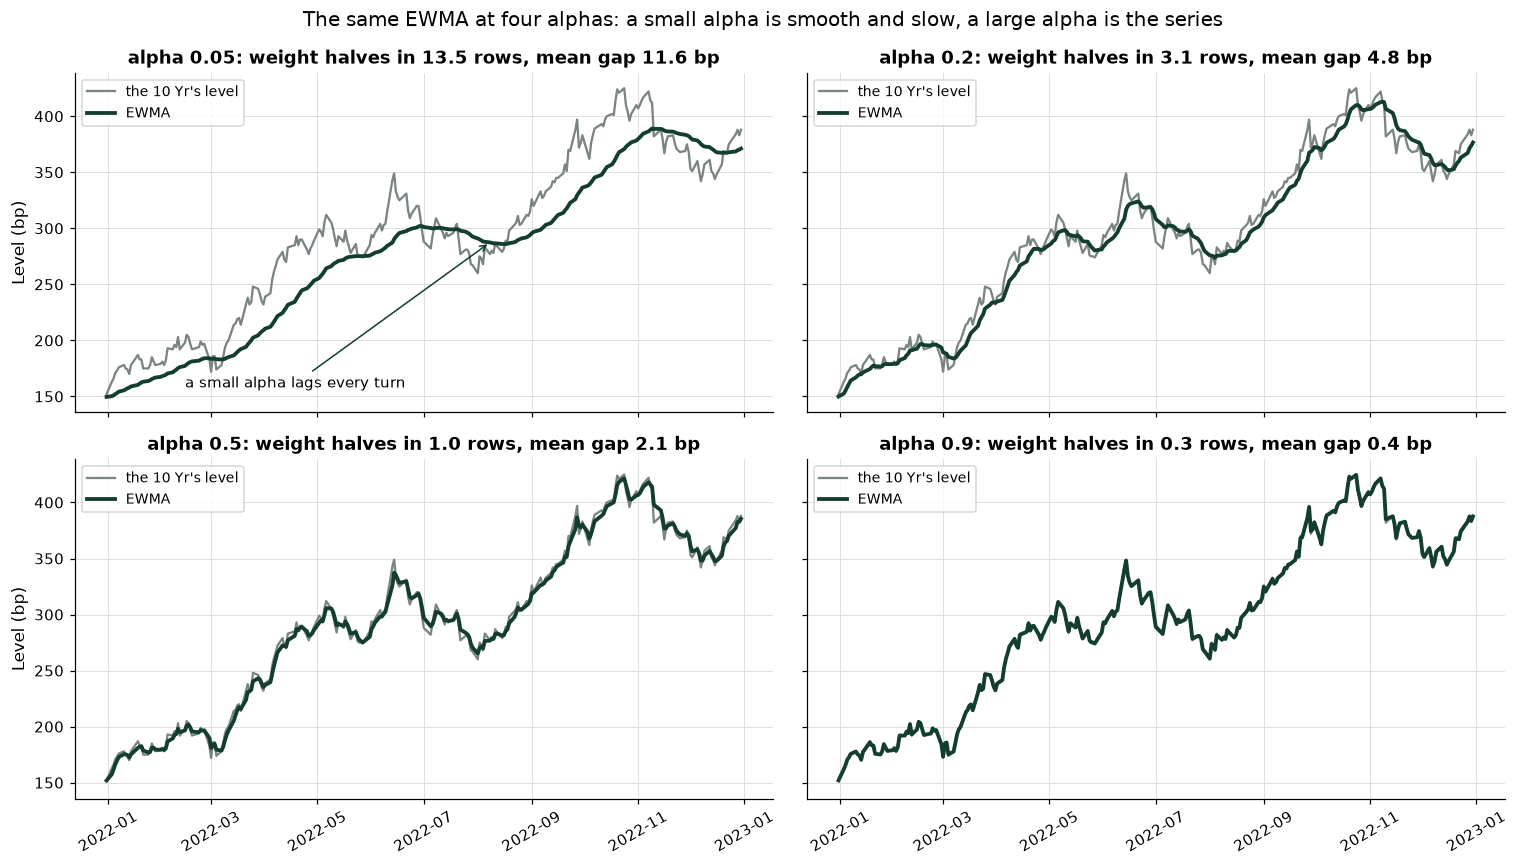

In [16]:
# the 10 Yr's last 250 development dates and its EWMA at four alphas: one setting changed per panel
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
window_dates = ten_year.index[-250:]
for ax, alpha in zip(axes.ravel(), alphas):
    ax.plot(window_dates, ten_year.loc[window_dates], color=plotkit.GREY, linewidth=1.5, label="the 10 Yr's level")
    ax.plot(window_dates, smoothed.loc[window_dates, alpha], color=plotkit.GREEN_DARK, linewidth=2.5, label="EWMA")
    ax.set_title(f"alpha {alpha}: weight halves in {weights.loc[alpha, 'rows until the weight halves']:.1f} rows, mean gap {weights.loc[alpha, 'mean gap to the series (bp)']:.1f} bp")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(loc="upper left", fontsize=9)
axes[0, 0].annotate("a small alpha lags every turn", xy=(window_dates[150], smoothed.loc[window_dates[150], 0.05]), xytext=(window_dates[30], ten_year.loc[window_dates].min() + 6),
                    arrowprops={"arrowstyle": "->", "color": plotkit.GREEN_DARK}, fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("Level (bp)")
fig.suptitle("The same EWMA at four alphas: a small alpha is smooth and slow, a large alpha is the series")
fig.tight_layout()
plt.show()

* How to read it: four panels, the same 250 dates, one setting changed. At alpha 0.05 the average is a slow curve that trails every turn by weeks, and a weight takes 13.5 rows to halve. At alpha 0.9 the average is the series with a small cushion, and a weight halves in 0.30 rows. The mean gap to the series falls from 11.6 bp to 0.4 bp. **Pick alpha by what the smoothing is for**: a description of a level's drift wants a small alpha, and a one-step value for a date wants whatever the scores say, which the later sections measure.

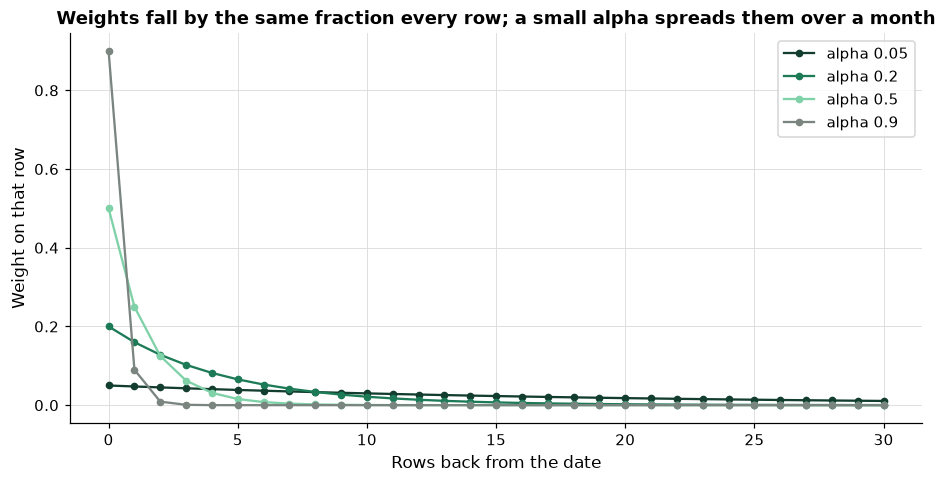

In [17]:
# the weight an EWMA puts on the value k rows back: alpha x (1 - alpha) to the power k
fig, ax = plt.subplots(figsize=(10, 4.6))
rows_back = np.arange(0, 31)
for alpha in alphas:
    ax.plot(rows_back, alpha * (1 - alpha) ** rows_back, marker="o", markersize=4, label=f"alpha {alpha}")
ax.set_xlabel("Rows back from the date")
ax.set_ylabel("Weight on that row")
ax.set_title("Weights fall by the same fraction every row; a small alpha spreads them over a month")
ax.legend(loc="upper right")
plt.show()

* The weights fall by the same fraction every row, so the picture is a curve with no kink. alpha 0.05 puts a weight of 0.05 on the newest row and 0.018 on the row 20 back, so a month of history still counts. alpha 0.5 keeps almost nothing beyond five rows back.

## 6.2 Simple Smoothing: Alpha by Least Squares

**How it works.** Simple exponential smoothing is the EWMA used as a value for the next row. The model says the next level is the average so far, plus a shock. Alpha is not chosen by eye: for each alpha the model's one-step value for every training row is the EWMA through the row before, the miss is the level less that value, and **alpha is the number that makes the sum of squared misses smallest**. The optimiser also fits the starting level. You control only whether those starting values are fitted or fixed; what comes out is alpha, the starting level, and the sum of squared misses. Alpha equal to 1 makes the value the last level, so the fit answers the question of how much averaging the data want.

Q. Add the one-step recursion from fixed coefficients, `smoothing_values`, and `fit_smoothing`, which fits by least squares through statsmodels.

In [18]:
%%writefile -a tskit.py


def smoothing_values(values, level0: float, alpha: float, trend0: float = 0.0, beta: float = 0.0, phi: float = 1.0) -> np.ndarray:
    """The one-step value of an exponential smoothing for every row, by the recursion, from fixed coefficients.

    Inputs: values, a one-dimensional array of levels in bp (a NaN stops the recursion from that row on); level0 and
    trend0, the state before the first row; alpha, beta, and phi, the weights on the newest level, on the newest trend,
    and the damping of the trend (1 means no damping). With trend0 = 0 and beta = 0 this is simple smoothing.
    Output: an array the length of values. Entry t is level[t-1] + phi x trend[t-1], the value for row t given only the
    rows before it, where level[t] = alpha x[t] + (1 - alpha)(level[t-1] + phi trend[t-1]) and
    trend[t] = beta (level[t] - level[t-1]) + (1 - beta) phi trend[t-1].
    """
    array = np.asarray(values, dtype=float)
    out = np.empty(len(array))
    level, trend = level0, trend0
    for row in range(len(array)):
        out[row] = level + phi * trend
        new_level = alpha * array[row] + (1 - alpha) * (level + phi * trend)
        trend = beta * (new_level - level) + (1 - beta) * phi * trend
        level = new_level
    return out


def fit_smoothing(values, trend: str | None = None, damped: bool = False, **settings):
    """Fit an exponential smoothing by least squares to a plain array and return statsmodels' results.

    Inputs: values, a one-dimensional array of floats with no blank (levels in bp); trend, None for simple smoothing
    or "add" for Holt's linear trend; damped, whether the trend is damped (needs trend="add"); settings, any other
    ExponentialSmoothing setting by name (initialization_method, bounds). The starting level and trend are estimated
    along with the weights, from these values only.
    Output: the fitted results; results.params holds smoothing_level, smoothing_trend, damping_trend, initial_level,
    and initial_trend (nan for a part the model does not have).
    The array goes in without its dates for the reason fit_arima gives: a series of trading days has no frequency.
    Raises ValueError for values with a blank or fewer than 10 numbers.
    """
    array = np.asarray(values, dtype=float)
    if array.ndim != 1 or len(array) < 10 or np.isnan(array).any():
        raise ValueError("values must be a one-dimensional array of at least 10 numbers with no blank")
    settings.setdefault("initialization_method", "estimated")
    return ExponentialSmoothing(array, trend=trend, damped_trend=damped, **settings).fit()

Appending to tskit.py


* `smoothing_values` is the recursion written out: the state before the first row, then for each row a value, a new level, and a new trend. With no trend it is the EWMA used as a value. It stands in for statsmodels' own fitted values, because it takes any NaN row and carries it on, which the walk-forward proof needs, and because Excel can reproduce it row by row.
* `fit_smoothing` takes a plain array for the reason `fit_arima` does, and passes any other `ExponentialSmoothing` setting by name.

Q. Write the tests: the recursion equals statsmodels' fitted values for simple, Holt, and damped Holt, and alpha equal to 1 is the last value.

In [19]:
%%writefile -a test_tskit.py


def test_smoothing_values_equal_statsmodels_fitted_values():
    values = level_series().to_numpy()
    for trend, damped in ((None, False), ("add", False), ("add", True)):
        results = tskit.fit_smoothing(values, trend=trend, damped=damped)
        p = results.params
        found = tskit.smoothing_values(values, p["initial_level"], p["smoothing_level"],
                                       trend0=float(p["initial_trend"]) if trend else 0.0,
                                       beta=float(p["smoothing_trend"]) if trend else 0.0,
                                       phi=float(p["damping_trend"]) if damped else 1.0)
        assert found == pytest.approx(results.fittedvalues, abs=1e-6)


def test_simple_smoothing_with_alpha_one_is_the_last_value():
    values = level_series(rows=50).to_numpy()
    found = tskit.smoothing_values(values, values[0], 1.0)
    assert found[1:] == pytest.approx(values[:-1], abs=1e-12)

Appending to test_tskit.py


Q. Reload the modules and run the tests.

In [20]:
# the files changed, so reload before using the new functions
importlib.reload(tskit)
print(f"smoothing_values and fit_smoothing in tskit: {hasattr(tskit, 'smoothing_values') and hasattr(tskit, 'fit_smoothing')}")

smoothing_values and fit_smoothing in tskit: True


In [21]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...............................                                          [100%]
31 passed in 3.84s



* `31 passed`.

Q. Fit simple smoothing to the first training window of three series, and check that it is the EWMA.

In [22]:
# alpha chosen by least squares on the first training window, for three series
first_rows = splits[0][0]
alpha_rows = []
for name in ["10 Yr", "2s10s", "IG"]:
    window = levels[name].iloc[first_rows].to_numpy()
    fit = tskit.fit_smoothing(window)
    alpha_rows.append({"series": name, "alpha": fit.params["smoothing_level"], "starting level (bp)": fit.params["initial_level"],
                       "first value (bp)": window[0], "sum of squared misses (bp squared)": fit.sse})
alpha_table = pd.DataFrame(alpha_rows).set_index("series")
print(alpha_table.round(4).to_string())

# simple smoothing IS the EWMA: with the starting level set to the first value, statsmodels' one-step values are the EWMA, one row later
window = levels["10 Yr"].iloc[first_rows].to_numpy()
known = tskit.fit_smoothing(window, initialization_method="known", initial_level=window[0])
by_ewma = tskit.ewma(pd.Series(window), known.params["smoothing_level"]).to_numpy()
gap = np.abs(known.fittedvalues[1:] - by_ewma[:-1]).max()
print(f"alpha {known.params['smoothing_level']:.4f}; statsmodels' one-step values equal the EWMA of the row before within 1e-8: {bool(gap < 1e-8)}")

plotkit.styled(alpha_table, [], "Least-squares alpha of simple smoothing on the first training window (504 dates)", fmt="{:.4f}")

         alpha  starting level (bp)  first value (bp)  sum of squared misses (bp squared)
series                                                                                   
10 Yr   0.9426             211.5175             212.0                          12276.9503
2s10s   0.9173             145.1471             146.0                           5168.6125
IG      0.8947              90.2570              90.3                            508.4111
alpha 0.9430; statsmodels' one-step values equal the EWMA of the row before within 1e-8: True


,alpha,starting level (bp),first value (bp),sum of squared misses (bp squared)
series,,,,
10 Yr,0.9426,211.5175,212.0000,12276.9503
2s10s,0.9173,145.1471,146.0000,5168.6125
IG,0.8947,90.2570,90.3000,508.4111


* The least-squares alpha is 0.943 for the 10 Yr, 0.917 for the 2s10s, and 0.895 for the invented IG spread: all close to 1. With the starting level fixed at the first value, simple smoothing's one-step values *are* the EWMA of the row before, to 1e-8: simple smoothing and the EWMA are one model, and the fit is only the choice of alpha.

Q. Draw the sum of squared misses against alpha for each series, so the choice of alpha is visible.

In [23]:
# the sum of squared one-step misses on the first training window against alpha, per series (starting level = the first value)
grid = np.round(np.arange(0.02, 1.0001, 0.02), 2)
sse = {}
for name in ["10 Yr", "2s10s", "IG"]:
    window = levels[name].iloc[first_rows].to_numpy()
    sse[name] = [((window - tskit.smoothing_values(window, window[0], alpha)) ** 2).sum() for alpha in grid]
sse = pd.DataFrame(sse, index=pd.Index(grid, name="alpha"))
best_alpha = sse.idxmin()
print(best_alpha.to_string())
print(f"the 10 Yr's least-squares alpha on this grid {best_alpha['10 Yr']:.2f}, from statsmodels with the same starting level {known.params['smoothing_level']:.4f}")

10 Yr    0.94
2s10s    0.92
IG       0.90
the 10 Yr's least-squares alpha on this grid 0.94, from statsmodels with the same starting level 0.9430


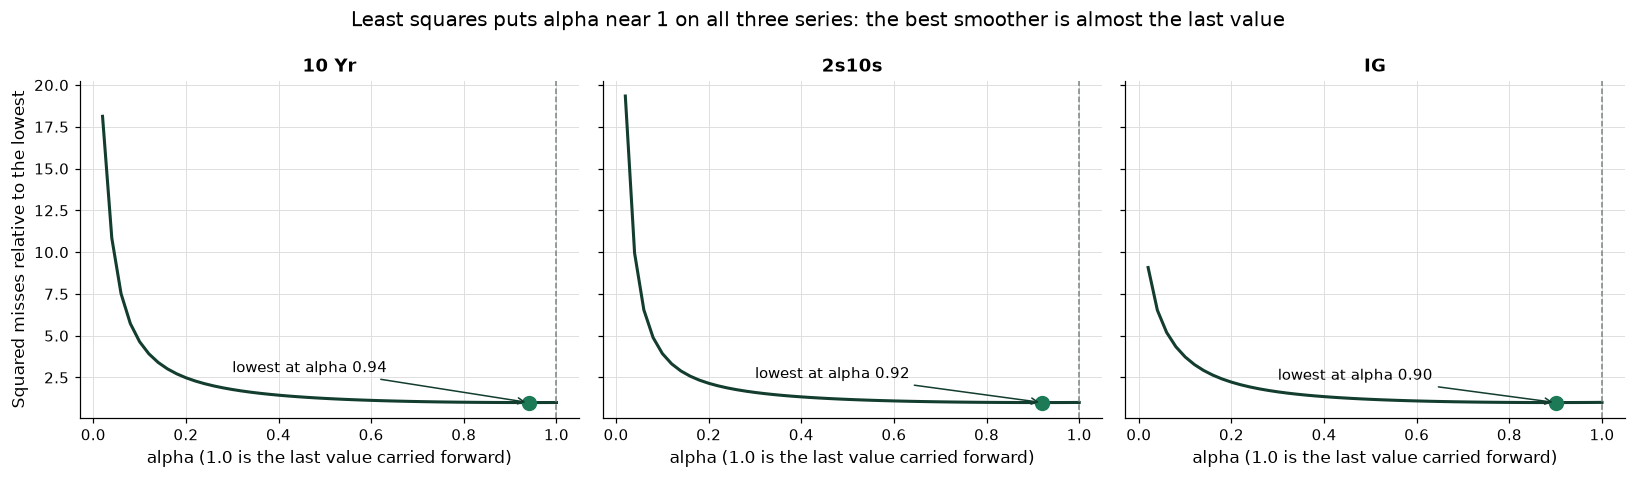

In [24]:
# the sum of squared one-step misses against alpha, per series, relative to its lowest value
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, name in zip(axes, sse.columns):
    relative = sse[name] / sse[name].min()
    ax.plot(sse.index, relative, color=plotkit.GREEN_DARK, linewidth=2)
    ax.plot([best_alpha[name]], [1.0], "o", color=plotkit.GREEN, markersize=9)
    ax.annotate(f"lowest at alpha {best_alpha[name]:.2f}", xy=(best_alpha[name], 1.0), xytext=(0.3, 1.0 + 0.5 * (relative.iloc[4] - 1.0)),
                arrowprops={"arrowstyle": "->", "color": plotkit.GREEN_DARK}, fontsize=10)
    ax.axvline(1.0, color=plotkit.GREY, linestyle="--", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("alpha (1.0 is the last value carried forward)")
axes[0].set_ylabel("Squared misses relative to the lowest")
fig.suptitle("Least squares puts alpha near 1 on all three series: the best smoother is almost the last value")
fig.tight_layout()
plt.show()

* How to read it: each curve is a bowl, and the lowest point is the least-squares alpha: 0.94 for the 10 Yr on this grid, against 0.9430 from statsmodels with the same starting level. Moving alpha down to 0.1 makes the 10 Yr's squared misses 4.6 times as large. The data want almost no averaging: a level that is close to a random walk has nothing to smooth.

## 6.3 Holt's Linear Trend and the Damped Trend

**How it works.** Simple smoothing assumes the level has no direction. **Holt's method** keeps a second state, a **trend**: the average change per row. Each row it updates the level as before, now starting from the old level plus the old trend, and updates the trend as a weighted average (weight **beta**) of the latest change in the level and the old trend. The model's one-step value is level plus trend. A trend that is carried without end is a strong claim, so the **damped** version multiplies the trend by a factor **phi** below 1 each row, which fades it. You control whether there is a trend, whether it is damped, and the weights; what comes out is alpha, beta, phi, the starting level and trend, and AIC and BIC to compare the three on the same rows.

Q. Fit the three smoothers to the 10 Yr's first training window and compare their coefficients and information criteria.

In [25]:
# three smoothers fitted to the first training window of the 10 Yr: no trend, Holt's linear trend, and a damped trend
window = levels["10 Yr"].iloc[first_rows].to_numpy()
kinds = {"simple": (None, False), "Holt": ("add", False), "damped Holt": ("add", True)}
fits = {label: tskit.fit_smoothing(window, trend=trend, damped=damped) for label, (trend, damped) in kinds.items()}
model_rows = []
for label, fit in fits.items():
    p = fit.params
    model_rows.append({"model": label, "alpha": p["smoothing_level"], "beta": p["smoothing_trend"], "phi": p["damping_trend"],
                       "starting level (bp)": p["initial_level"], "starting trend (bp a row)": p["initial_trend"],
                       "AIC": fit.aic, "BIC": fit.bic})
model_table = pd.DataFrame(model_rows).set_index("model")
print(model_table.round(4).to_string())

plotkit.styled(model_table, ["AIC", "BIC"], "Three smoothers on the 10 Yr, first training window: coefficients and information criteria", higher_is_better=False, fmt="{:.4f}")

              alpha  beta  phi  starting level (bp)  starting trend (bp a row)        AIC        BIC
model                                                                                               
simple       0.9426   NaN  NaN             211.5175                        NaN  1613.2229  1621.6680
Holt         0.9423   0.0  NaN             211.4609                     0.0517  1617.1608  1634.0511
damped Holt  0.9361   0.0  0.8             219.2741                    -9.2682  1614.7660  1635.8789


,alpha,beta,phi,starting level (bp),starting trend (bp a row),AIC,BIC
model,,,,,,,
simple,0.9426,,,211.5175,,1613.2229,1621.6680
Holt,0.9423,0.0000,,211.4609,0.0517,1617.1608,1634.0511
damped Holt,0.9361,0.0000,0.8000,219.2741,-9.2682,1614.7660,1635.8789


* Simple smoothing has the lowest AIC (1613.22, against 1617.16 for Holt and 1614.77 for the damped trend): the extra trend term and its weight cost more than they fit. The fitted beta for Holt is 0.0000: the optimiser leaves the trend exactly where it started, so Holt's trend is a constant drift term and never learns from the data. The damped version's phi is 0.80, which is the bottom of the range the optimiser is allowed (the `bounds` row in the settings table).

Q. Draw the three smoothers' one-step values for 60 test dates, and each less the last value: the fitted change.

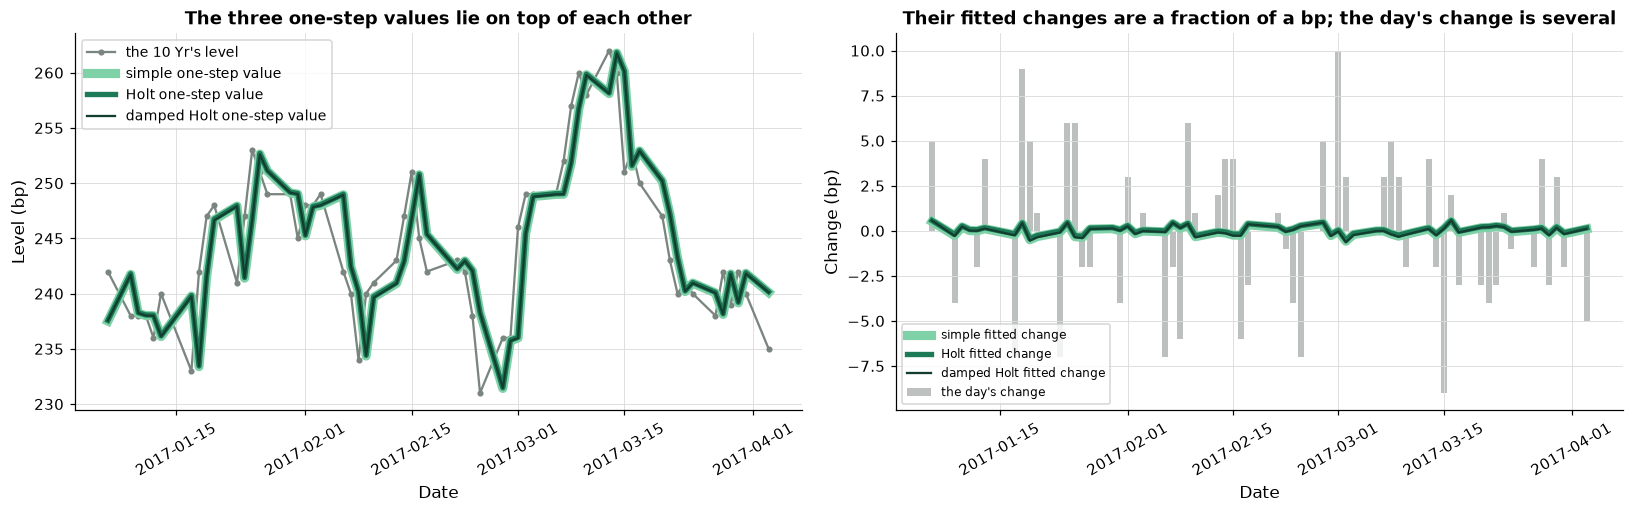

In [26]:
# the first 60 dates of fold 1's test window: one-step values of three smoothers, and each less the last value (the fitted change)
test_rows = splits[0][1][:60]
test_dates = levels.index[test_rows]
all_levels = levels["10 Yr"].to_numpy()
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 4.8))
left.plot(test_dates, all_levels[test_rows], color=plotkit.GREY, linewidth=1.5, marker="o", markersize=3, label="the 10 Yr's level")
actual_change = all_levels[test_rows] - all_levels[test_rows - 1]
right.bar(test_dates, actual_change, color=plotkit.GREY, alpha=0.5, label="the day's change")
for label, color, width in zip(kinds, [plotkit.GREEN_LIGHT, plotkit.GREEN, plotkit.GREEN_DARK], [6, 3.5, 1.5]):
    trend, damped = kinds[label]
    p = fits[label].params
    values = tskit.smoothing_values(all_levels[:test_rows[-1] + 1], p["initial_level"], p["smoothing_level"],
                                    float(p["initial_trend"]) if trend else 0.0, float(p["smoothing_trend"]) if trend else 0.0,
                                    float(p["damping_trend"]) if damped else 1.0)[test_rows]
    left.plot(test_dates, values, color=color, linewidth=width, label=f"{label} one-step value")
    right.plot(test_dates, values - all_levels[test_rows - 1], color=color, linewidth=width, label=f"{label} fitted change")
left.set_xlabel("Date")
left.set_ylabel("Level (bp)")
left.set_title("The three one-step values lie on top of each other")
left.tick_params(axis="x", rotation=30)
left.legend(loc="upper left", fontsize=9)
right.set_xlabel("Date")
right.set_ylabel("Change (bp)")
right.set_title("Their fitted changes are a fraction of a bp; the day's change is several")
right.tick_params(axis="x", rotation=30)
right.legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

* **Left:** the three one-step values lie on top of one another and a step behind the level, because alpha is near 1 and the trend barely moves them. **Right:** the same values less the last value, which is the fitted change. They are a fraction of a bp, in a window where the day's change is several. The smoothing says almost nothing about the next change, which is day 5's finding in another model.

Q. Holt's alpha and beta together: draw the in-sample one-step MAE over a grid.

In [27]:
# the in-sample one-step MAE on the first training window for alpha across and beta down (starting level = first value, trend 0)
alpha_axis = np.round(np.arange(0.1, 1.0001, 0.1), 1)
beta_axis = [0.0, 0.02, 0.05, 0.1, 0.2, 0.4]
ab = pd.DataFrame(index=pd.Index(beta_axis, name="beta"), columns=pd.Index(alpha_axis, name="alpha"), dtype=float)
for beta in beta_axis:
    for alpha in alpha_axis:
        ab.loc[beta, alpha] = np.abs(window - tskit.smoothing_values(window, window[0], alpha, 0.0, beta)).mean()
best_beta, best_a = ab.stack().idxmin()
print(f"lowest in-sample MAE {ab.stack().min():.4f} bp at alpha {best_a:.1f}, beta {best_beta:.2f}; alpha 1.0 with beta 0 (the last value): {ab.loc[0.0, 1.0]:.4f} bp")

lowest in-sample MAE 3.8869 bp at alpha 1.0, beta 0.00; alpha 1.0 with beta 0 (the last value): 3.8869 bp


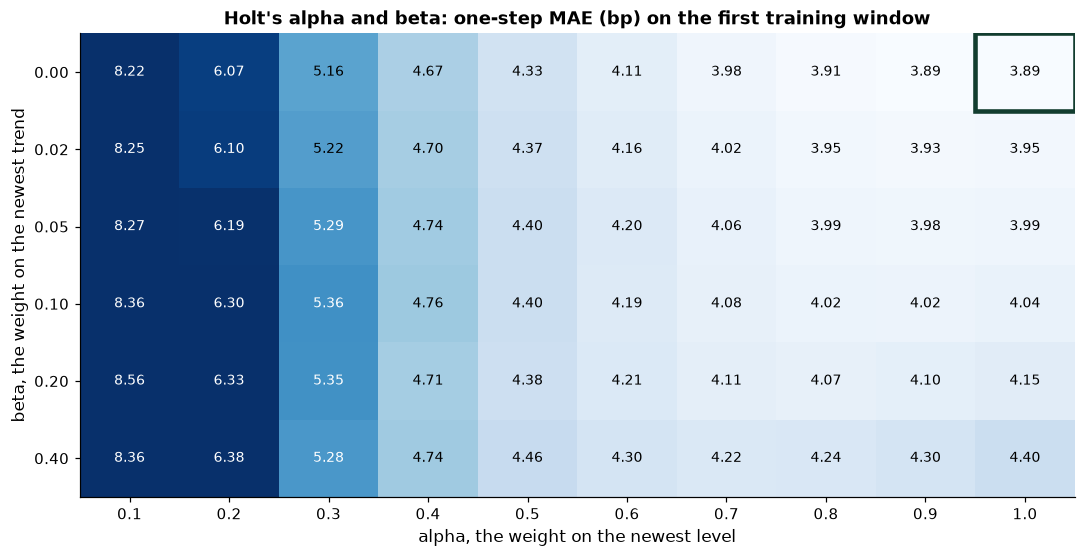

In [28]:
# in-sample one-step MAE for alpha across and beta down: darker is a larger miss; the lowest cell is outlined
fig, ax = plt.subplots(figsize=(10, 5.2))
values_ab = ab.to_numpy(dtype=float)
image = ax.imshow(values_ab, cmap="Blues", aspect="auto", vmin=values_ab.min(), vmax=np.percentile(values_ab, 85))
for row in range(values_ab.shape[0]):
    for column in range(values_ab.shape[1]):
        dark = values_ab[row, column] > values_ab.min() + 0.6 * (np.percentile(values_ab, 85) - values_ab.min())
        ax.text(column, row, f"{values_ab[row, column]:.2f}", ha="center", va="center", fontsize=9, color="white" if dark else "black")
best_row, best_column = np.unravel_index(values_ab.argmin(), values_ab.shape)
ax.add_patch(plt.Rectangle((best_column - 0.5, best_row - 0.5), 1, 1, fill=False, edgecolor=plotkit.GREEN_DARK, linewidth=3))
ax.set_xticks(range(len(alpha_axis)), [f"{a:.1f}" for a in alpha_axis])
ax.set_yticks(range(len(beta_axis)), [f"{b:.2f}" for b in beta_axis])
ax.set_xlabel("alpha, the weight on the newest level")
ax.set_ylabel("beta, the weight on the newest trend")
ax.set_title("Holt's alpha and beta: one-step MAE (bp) on the first training window")
ax.grid(False)
fig.tight_layout()
plt.show()

* How to read it: darker cells are larger misses, and the outlined cell is the lowest, at alpha 1.0 and beta 0.00: 3.8869 bp. **That cell is the last value carried forward**: alpha 1.0 with no trend. On this window no smaller alpha and no trend does better, even in-sample, where a model has every advantage. Moving left (more averaging) or down (more trend) raises the miss. This is an in-sample picture; the score that counts is walk-forward, below.

## 6.4 Every Setting of `ExponentialSmoothing`

Q. Read every setting of `ExponentialSmoothing` and its `fit`, with the defaults taken from the installed statsmodels.

In [29]:
import inspect

from statsmodels.tsa.holtwinters import ExponentialSmoothing

init_defaults = {name: p.default for name, p in inspect.signature(ExponentialSmoothing.__init__).parameters.items()}
fit_defaults = {name: p.default for name, p in inspect.signature(ExponentialSmoothing.fit).parameters.items()}
rows = [
    ("trend", init_defaults["trend"], "None for simple smoothing, 'add' for a linear trend", "'add' adds a trend term and a weight beta; the series here has none to find", "yes"),
    ("damped_trend", init_defaults["damped_trend"], "whether the trend fades by a factor phi each row", "True keeps a trend from running on forever; phi is fitted", "yes"),
    ("seasonal, seasonal_periods", init_defaults["seasonal"], "a repeating pattern of a fixed length", "none in daily rates, so the course leaves them off", "no"),
    ("initialization_method", init_defaults["initialization_method"], "how the starting level and trend are set: estimated, heuristic, legacy-heuristic, or known", "'estimated' fits them with the weights; 'known' needs initial_level", "yes"),
    ("initial_level, initial_trend", init_defaults["initial_level"], "the starting values when the method is 'known'", "setting the level to the first value makes simple smoothing the EWMA", "no"),
    ("use_boxcox", init_defaults["use_boxcox"], "a power transform before smoothing", "False: levels in bp are already on a plain scale", "no"),
    ("bounds", init_defaults["bounds"], "limits on each weight (None means 0 to 1 for alpha, beta, and a damping range)", "tighter bounds stop a weight from sitting on 0 or 1", "no"),
    ("dates, freq, missing", init_defaults["missing"], "a date index, its frequency, and what to do with a blank", "tskit passes plain arrays and no blank, so none is used", "no"),
    ("smoothing_level (fit)", fit_defaults["smoothing_level"], "alpha, fixed instead of fitted when given", "a fixed alpha with optimized=False is a rule, not a fit", "yes"),
    ("smoothing_trend, damping_trend (fit)", fit_defaults["smoothing_trend"], "beta and phi, fixed instead of fitted when given", "fixing them tests one value at a time", "no"),
    ("optimized (fit)", fit_defaults["optimized"], "True lets the optimiser choose every free weight", "False uses exactly the weights given", "no"),
    ("method, minimize_kwargs, use_brute, start_params (fit)", fit_defaults["use_brute"], "how the optimiser searches", "use_brute starts from a grid of values: slower and steadier", "no"),
    ("remove_bias (fit)", fit_defaults["remove_bias"], "shifts the fitted values so the average miss is zero", "True hides a bias the course wants to see", "no"),
]
settings_table = pd.DataFrame(rows, columns=["setting", "default", "what it controls", "raising it or turning it on", "tune first"]).set_index("setting")
settings_table["default"] = settings_table["default"].map(repr)

plotkit.styled(settings_table, [], "Every setting of ExponentialSmoothing: the defaults read from the installed statsmodels")

,default,what it controls,raising it or turning it on,tune first
setting,,,,
trend,None,"None for simple smoothing, 'add' for a linear trend",'add' adds a trend term and a weight beta; the series here has none to find,yes
damped_trend,False,whether the trend fades by a factor phi each row,True keeps a trend from running on forever; phi is fitted,yes
"seasonal, seasonal_periods",None,a repeating pattern of a fixed length,"none in daily rates, so the course leaves them off",no
initialization_method,'estimated',"how the starting level and trend are set: estimated, heuristic, legacy-heuristic, or known",'estimated' fits them with the weights; 'known' needs initial_level,yes
"initial_level, initial_trend",None,the starting values when the method is 'known',setting the level to the first value makes simple smoothing the EWMA,no
use_boxcox,False,a power transform before smoothing,False: levels in bp are already on a plain scale,no
bounds,None,"limits on each weight (None means 0 to 1 for alpha, beta, and a damping range)",tighter bounds stop a weight from sitting on 0 or 1,no
"dates, freq, missing",'none',"a date index, its frequency, and what to do with a blank","tskit passes plain arrays and no blank, so none is used",no
smoothing_level (fit),None,"alpha, fixed instead of fitted when given","a fixed alpha with optimized=False is a rule, not a fit",yes


* Four settings matter, marked "tune first": `trend`, `damped_trend`, `initialization_method`, and a fixed `smoothing_level`. Alpha, beta, and phi are fitted by default; the sweeps above showed alpha (the bowl) and alpha with beta (the heatmap). The sweeps below take the other two.

Q. Sweep the starting level: four ways to set it, on the 10 Yr's first training window.

In [30]:
# the starting level: four ways to set it, on the 10 Yr's first training window
init_rows = []
for method in ["estimated", "heuristic", "legacy-heuristic", "known"]:
    settings = {"initial_level": window[0]} if method == "known" else {}
    fit = tskit.fit_smoothing(window, initialization_method=method, **settings)
    init_rows.append({"initialization_method": method, "alpha": fit.params["smoothing_level"], "starting level (bp)": fit.params["initial_level"],
                      "sum of squared misses (bp squared)": fit.sse})
init_sweep = pd.DataFrame(init_rows).set_index("initialization_method")
print(init_sweep.round(4).to_string())

plotkit.styled(init_sweep, ["sum of squared misses (bp squared)"], "Simple smoothing by initialization_method, first training window of the 10 Yr", higher_is_better=False, fmt="{:.4f}")

                        alpha  starting level (bp)  sum of squared misses (bp squared)
initialization_method                                                                 
estimated              0.9426             211.5175                          12276.9503
heuristic              0.9429             211.8667                          12277.0717
legacy-heuristic       0.9430             212.0000                          12277.1822
known                  0.9430             212.0000                          12277.1822


,alpha,starting level (bp),sum of squared misses (bp squared)
initialization_method,,,
estimated,0.9426,211.5175,12276.9503
heuristic,0.9429,211.8667,12277.0717
legacy-heuristic,0.9430,212.0000,12277.1822
known,0.9430,212.0000,12277.1822


* The four starting levels give alphas within 0.0004 of each other, and starting levels within a few bp: **the starting value matters for the first rows and fades after**, because the weight on it shrinks by (1 - alpha) every row. With alpha near 1 it fades in a row or two. `walk_forward_smoothing` uses the estimated start from each fold's training rows only.

Q. Fix alpha as a rule and score it walk-forward on day 2's folds, for alpha from 0.05 to 1.0.

In [31]:
# a fixed alpha as a rule, walk-forward: the recursion starts at the first value, so each date's value uses only the rows before it
alpha_grid = np.round(np.arange(0.05, 1.0001, 0.05), 2)
curve = {}
for name in ["10 Yr", "2s10s", "IG"]:
    values_all = levels[name].to_numpy()
    curve[name] = [np.mean([np.abs(values_all[test] - tskit.smoothing_values(values_all, values_all[0], alpha)[test]).mean() for _, test in splits])
                   for alpha in alpha_grid]
curve = pd.DataFrame(curve, index=pd.Index(alpha_grid, name="alpha"))
gap_to_last = curve - curve.loc[1.0]
print(f"walk-forward MAE with alpha 1.0, which is the last value: {curve.loc[1.0].round(4).to_dict()}")
print(f"lowest walk-forward MAE at alpha {curve.idxmin().to_dict()}; alpha 0.5 is {gap_to_last.loc[0.5].round(3).to_dict()} bp above the last value")

walk-forward MAE with alpha 1.0, which is the last value: {'10 Yr': 3.1937, '2s10s': 2.1548, 'IG': 0.8017}
lowest walk-forward MAE at alpha {'10 Yr': 1.0, '2s10s': 1.0, 'IG': 1.0}; alpha 0.5 is {'10 Yr': 0.432, '2s10s': 0.286, 'IG': 0.088} bp above the last value


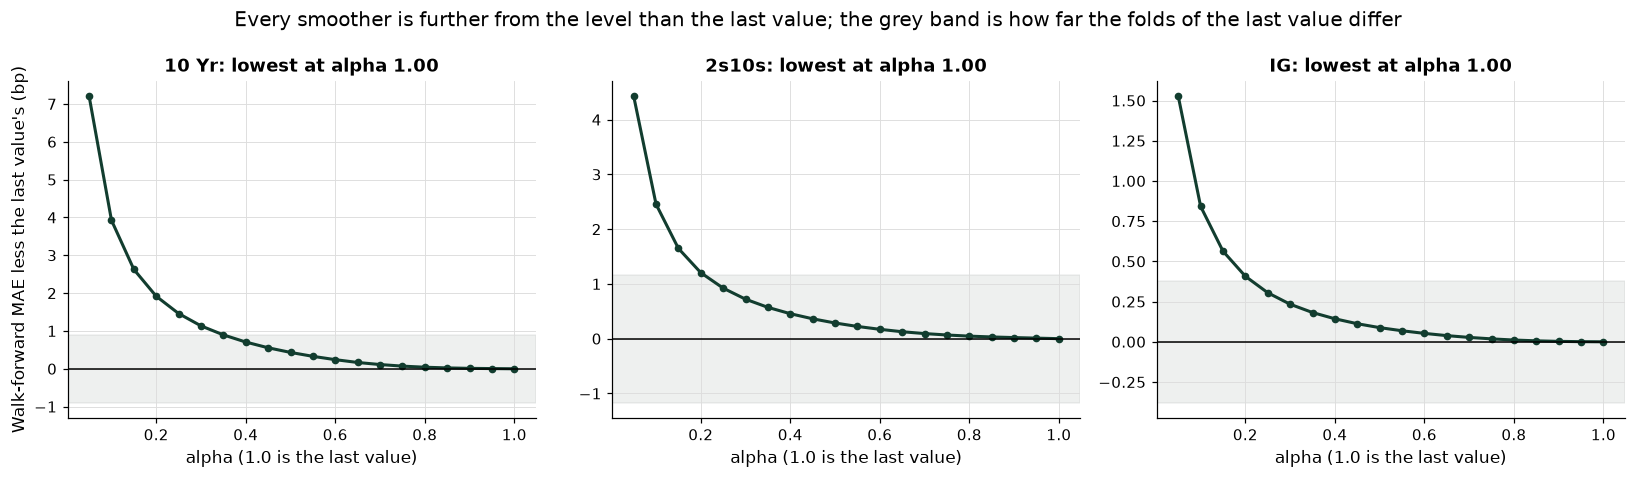

In [32]:
# walk-forward MAE with a fixed alpha, less the last value's (alpha 1.0): above zero is further from the level than the last value
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, name in zip(axes, gap_to_last.columns):
    ax.plot(gap_to_last.index, gap_to_last[name], color=plotkit.GREEN_DARK, linewidth=2, marker="o", markersize=4)
    ax.axhline(0, color="black", linewidth=1)
    ax.axhspan(-(last_mae[name].max() - last_mae[name].min()), last_mae[name].max() - last_mae[name].min(), color=plotkit.GREY, alpha=0.12)
    ax.set_title(f"{name}: lowest at alpha {gap_to_last[name].idxmin():.2f}")
    ax.set_xlabel("alpha (1.0 is the last value)")
axes[0].set_ylabel("Walk-forward MAE less the last value's (bp)")
fig.suptitle("Every smoother is further from the level than the last value; the grey band is how far the folds of the last value differ")
fig.tight_layout()
plt.show()

* How to read it: each dot is a fixed alpha, and its height is the walk-forward MAE less the last value's. The curves fall as alpha rises and reach zero at alpha 1.0, so **the best fixed alpha on every series is 1.00 or above: the last value**. Alpha 0.5 is 0.43 bp above it for the 10 Yr, 0.29 for the 2s10s, and 0.09 for the IG spread, far more than the least-squares alpha costs.

## 6.5 Walk-Forward Smoothing

**How it works.** Walk-forward scoring of a smoothing is day 2's recipe with a model in the middle. In each fold the weights and the starting state are **fitted once**, on the training rows only. Then the recursion runs through the training rows and on through the fold's rows with those weights held fixed, so the one-step value for each test row uses only the rows before it. At the next fold the model is fitted again on a longer window. You control the trend and the damping and the folds; what comes out is a table of MAE and RMSE by fold and one value per test date. The proof of `walk_forward_score` runs every time: the values must not move when the rows from the middle of the fold on are removed.

Q. Add `walk_forward_smoothing`, and the rest of today's tests.

In [33]:
%%writefile -a tskit.py


def walk_forward_smoothing(series: pd.Series, splits, trend: str | None = None, damped: bool = False,
                           check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score an exponential smoothing's one-step values fold by fold, walk-forward, with walk_forward_score's proof.

    Inputs: series, a dated Series of levels in bp with no NaN; splits, from mlkit.walk_forward_splits with gap 0;
    trend and damped, as for fit_smoothing; check, as for walk_forward_score.
    Each fold fits the weights and the starting state on its training rows only, then runs the recursion
    (smoothing_values) over the training rows and on through the fold's rows with those weights held fixed: the value
    for a test row uses only the rows before it. The weights are fitted again at the next fold.
    Output: (scores, values), as walk_forward_score returns them. The level folds are day 2's, so the last value
    carried forward scores day 2's numbers on the same dates.
    """
    fitted = {}

    def fit_one(history: pd.Series, n_train: int) -> np.ndarray:
        # the fit uses only the training rows, so it is shared by the proof's second run
        if n_train not in fitted:
            fitted[n_train] = fit_smoothing(history.iloc[:n_train].to_numpy(), trend=trend, damped=damped).params
        p = fitted[n_train]
        trended = trend is not None
        found = smoothing_values(history.to_numpy(), p["initial_level"], p["smoothing_level"],
                                 trend0=float(p["initial_trend"]) if trended else 0.0,
                                 beta=float(p["smoothing_trend"]) if trended else 0.0,
                                 phi=float(p["damping_trend"]) if damped else 1.0)
        return found[n_train:]

    return walk_forward_score(series, fit_one, splits, check=check)

Appending to tskit.py


* It is `walk_forward_score` with a rule: `fit_one` fits once, shares the fit with the proof's second run, runs the recursion over all the rows it is given, and returns the values from the first test row on.

Q. Write the tests: the values before a changed row do not move, smoothing beats the last value on a noisy level, and the refusals.

In [34]:
%%writefile -a test_tskit.py


def test_walk_forward_smoothing_uses_only_the_past():
    series = level_series(rows=200)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=100, test_size=40)
    _, values = tskit.walk_forward_smoothing(series, splits)
    # change every row from position 150 on: no value dated before position 150 may move
    other = series.copy()
    other.iloc[150:] = other.iloc[150:] + 20.0
    _, again = tskit.walk_forward_smoothing(other, splits, check=False)
    assert values.iloc[:150].equals(again.iloc[:150])
    assert not values.iloc[150:160].equals(again.iloc[150:160])


def test_smoothing_beats_the_last_value_on_a_noisy_level():
    series = level_series(rows=500)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=200, test_size=100)
    smooth, _ = tskit.walk_forward_smoothing(series, splits)
    last = [tskit.mae(series.iloc[test], series.shift(1).iloc[test]) for _, test in splits]
    assert (smooth["mae"].to_numpy() < np.array(last)).all()


def test_fit_smoothing_refusals():
    values = level_series().to_numpy()
    blank = values.copy()
    blank[5] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.fit_smoothing(blank)
    with pytest.raises(ValueError, match="at least 10"):
        tskit.fit_smoothing(values[:5])

Appending to test_tskit.py


Q. Reload the modules and run the tests.

In [35]:
# the files changed, so reload before using the new function
importlib.reload(tskit)
print(f"walk_forward_smoothing in tskit: {hasattr(tskit, 'walk_forward_smoothing')}")

walk_forward_smoothing in tskit: True


In [36]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..................................                                       [100%]
34 passed in 3.68s



* `34 passed`: day 5's 27 and today's seven. The noisy-level test is the one where smoothing *should* win, on a series built to be a slow level plus noise: it shows the code can win when the data allow.

Q. Score the smoothers on three series, beside the last value, the drift, and day 5's AR(1).

In [37]:
def score_series(name):
    """Walk-forward MAE by fold of six rules on one series: day 2's level folds, and day 5's AR(1) on the changes."""
    series = levels[name]
    columns = {"last value": last_mae[name].to_list()}
    drift, _ = tskit.walk_forward_score(series, lambda history, n_train: tskit.naive_values(history, "drift", n_train).to_numpy(), splits)
    columns["drift"] = drift["mae"].to_list()
    for label, trend, damped in [("simple smoothing", None, False), ("Holt", "add", False), ("damped Holt", "add", True)]:
        scores, _ = tskit.walk_forward_smoothing(series, splits, trend=trend, damped=damped)
        columns[label] = scores["mae"].to_list()
    ar1, _ = tskit.walk_forward_arima(changes[name], (1, 0, 0), change_splits)
    columns["AR(1)"] = ar1["mae"].to_list()
    return pd.DataFrame(columns, index=pd.Index(range(1, len(splits) + 1), name="fold"))


results = {name: score_series(name) for name in ["10 Yr", "2s10s", "IG"]}
score_rows = []
for name, table in results.items():
    for model in table.columns[1:]:
        score_rows.append({"series": name, "model": model, "mean MAE (bp)": table[model].mean(), "last value (bp)": table["last value"].mean(),
                           "gap to the last value (bp)": table[model].mean() - table["last value"].mean(),
                           "MASE": table[model].mean() / table["last value"].mean(),
                           "folds below the last value": int((table[model] < table["last value"]).sum()),
                           "folds of the last value, range (bp)": table["last value"].max() - table["last value"].min()})
score_table = pd.DataFrame(score_rows).set_index(["series", "model"])
print(score_table[["mean MAE (bp)", "gap to the last value (bp)", "MASE", "folds below the last value"]].round(4).to_string())

plotkit.styled(score_table, ["MASE"], "Three series: walk-forward MAE of five rules against the last value carried forward, day 2's five folds",
               higher_is_better=False, fmt="{:.4f}")

                         mean MAE (bp)  gap to the last value (bp)    MASE  folds below the last value
series model                                                                                          
10 Yr  drift                    3.2012                      0.0076  1.0024                           0
       simple smoothing         3.1996                      0.0059  1.0019                           3
       Holt                     3.2025                      0.0088  1.0028                           1
       damped Holt              3.2002                      0.0066  1.0021                           3
       AR(1)                    3.2026                      0.0089  1.0028                           1
2s10s  drift                    2.1682                      0.0134  1.0062                           0
       simple smoothing         2.1683                      0.0135  1.0063                           0
       Holt                     2.1702                      0.0155  1.007

<styled table: Three series: walk-forward MAE of five rules against the last value carried forward, day 2's five folds>

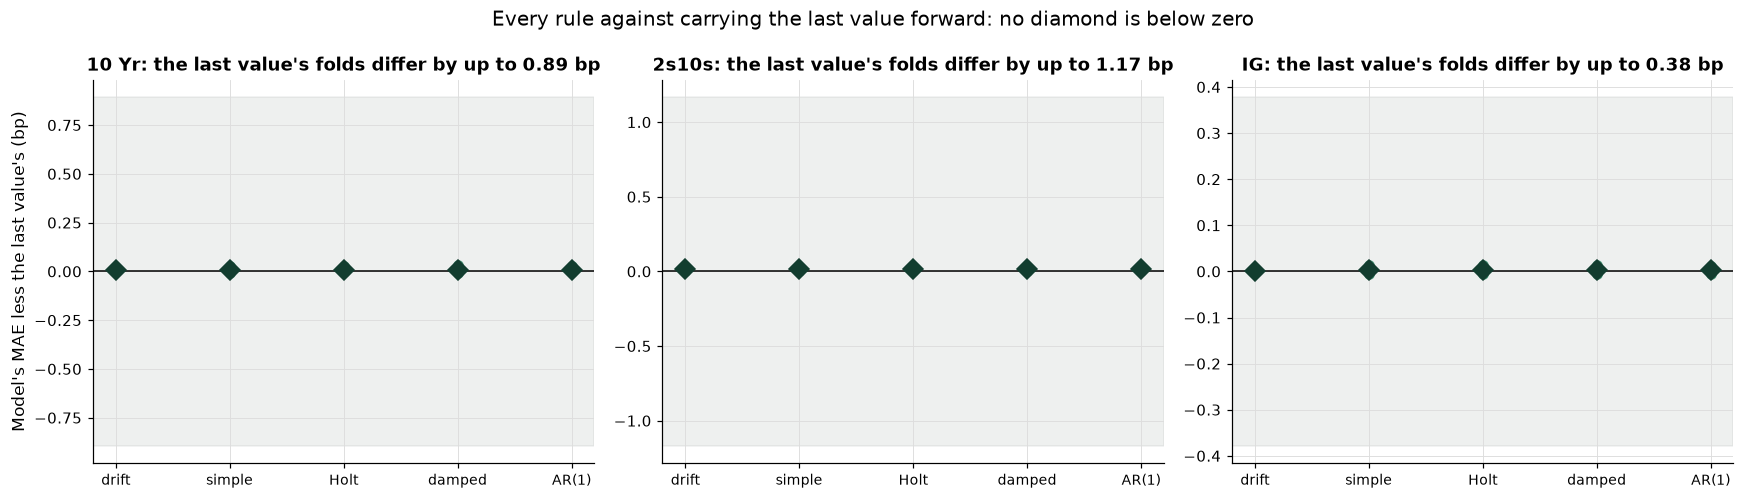

In [38]:
# three series, five rules: each dot is one fold's MAE less the last value's; diamonds are five-fold averages; the grey band is the folds' range
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (name, table) in zip(axes, results.items()):
    spread = table["last value"].max() - table["last value"].min()
    ax.axhspan(-spread, spread, color=plotkit.GREY, alpha=0.12)
    ax.axhline(0, color="black", linewidth=1)
    for number, column in enumerate(table.columns[1:]):
        ax.plot([number] * len(table), table[column] - table["last value"], "o", color=plotkit.GREEN, alpha=0.7)
        ax.plot([number], [table[column].mean() - table["last value"].mean()], "D", color=plotkit.GREEN_DARK, markersize=9)
    ax.set_xticks(range(5), ["drift", "simple", "Holt", "damped", "AR(1)"], fontsize=9)
    ax.set_title(f"{name}: the last value's folds differ by up to {spread:.2f} bp")
axes[0].set_ylabel("Model's MAE less the last value's (bp)")
fig.suptitle("Every rule against carrying the last value forward: no diamond is below zero")
fig.tight_layout()
plt.show()

* **No rule is closer than the last value on the five-fold average**: every MASE is above 1, the lowest is 1.0003. On the 10 Yr the last value is 3.1937 bp and simple smoothing is 3.1996, Holt 3.2025, the damped trend 3.2002, the drift 3.2012, and the AR(1) 3.2026.
* **Some folds go the other way.** On the 10 Yr, simple smoothing is below the last value on 3 of 5 folds and the damped trend on 3, and the average is still above. Every gap is far inside the grey band, which is how far the last value's own folds differ.
* A trend does not help. On the 10 Yr Holt's linear trend (3.2025 bp) is no closer than simple smoothing (3.1996), and the damped version sits between them: the trend term is the part of the model with nothing to fit.

## 6.6 The EWMA of Squared Changes: a Volatility Description

**How it works.** Squared changes are a measure of how big the days are, and day 4 found that they have long memory: big days follow big days. An EWMA of the squared change is an estimate of the day's **variance** that keeps that memory, and its square root is a **volatility** in bp a day. J.P. Morgan's RiskMetrics method is exactly this recursion, with the weight on the old variance written **lambda**: variance now = lambda x variance before + (1 - lambda) x the latest change squared, so alpha = 1 - lambda. RiskMetrics' Technical Document (4th edition, December 1996) sets lambda at **0.94** for daily data and 0.97 for monthly data (source: [RiskMetrics Technical Document, MSCI](https://www.msci.com/research-and-insights/paper/1996-riskmetrics-technical-document), the passage on the two decay factors). You control lambda; what comes out is a volatility for every date.

Q. Compute the EWMA volatility of the 10 Yr's changes at three lambdas, beside a 20-row rolling value, and find which lambda describes the size of the next change best over the development years.

In [39]:
# RiskMetrics' EWMA of squared changes: variance[t] = lambda variance[t-1] + (1 - lambda) change[t] squared, so alpha = 1 - lambda
ten_changes = changes["10 Yr"]
lambdas = [0.80, 0.94, 0.97]
volatility = pd.DataFrame({lam: np.sqrt(tskit.ewma(ten_changes ** 2, 1 - lam)) for lam in lambdas})
volatility["20-row rolling"] = ten_changes.rolling(20).std()
print(f"volatility of the 10 Yr's daily change on {ten_changes.index[-1].date()}, in bp: " + ", ".join(f"{c} {volatility[c].iloc[-1]:.2f}" for c in volatility.columns))

# which decay describes the next day's absolute change best over the development years? The value for a date uses the variance of the row before.
lambda_grid = np.round(np.arange(0.70, 0.9951, 0.005), 3)
mae_by_lambda = []
for lam in lambda_grid:
    vol_before = np.sqrt(tskit.ewma(ten_changes ** 2, 1 - lam)).shift(1)
    mae_by_lambda.append((ten_changes.abs() - np.sqrt(2 / np.pi) * vol_before).abs().dropna().mean())
mae_by_lambda = pd.Series(mae_by_lambda, index=pd.Index(lambda_grid, name="lambda"))
constant_mae = (ten_changes.abs() - ten_changes.abs().mean()).abs().mean()
print(f"lowest MAE of the size of the change: lambda {mae_by_lambda.idxmin():.3f}, {mae_by_lambda.min():.4f} bp; lambda 0.94: {mae_by_lambda.loc[0.94]:.4f} bp; a constant size: {constant_mae:.4f} bp")

plotkit.styled(volatility.describe().loc[["mean", "std", "min", "max"]].T.rename(index=str), [], "Volatility of the 10 Yr's daily change in bp, development years: three decays and a 20-row rolling value", fmt="{:.3f}")

volatility of the 10 Yr's daily change on 2022-12-30, in bp: 0.8 6.25, 0.94 7.49, 0.97 8.03, 20-row rolling 6.89
lowest MAE of the size of the change: lambda 0.940, 2.2979 bp; lambda 0.94: 2.2979 bp; a constant size: 2.4274 bp


,mean,std,min,max
0.8,4.595,2.055,1.288,18.059
0.94,4.730,1.724,2.325,13.135
0.97,4.780,1.556,2.915,10.519
20-row rolling,4.654,1.871,1.932,14.514


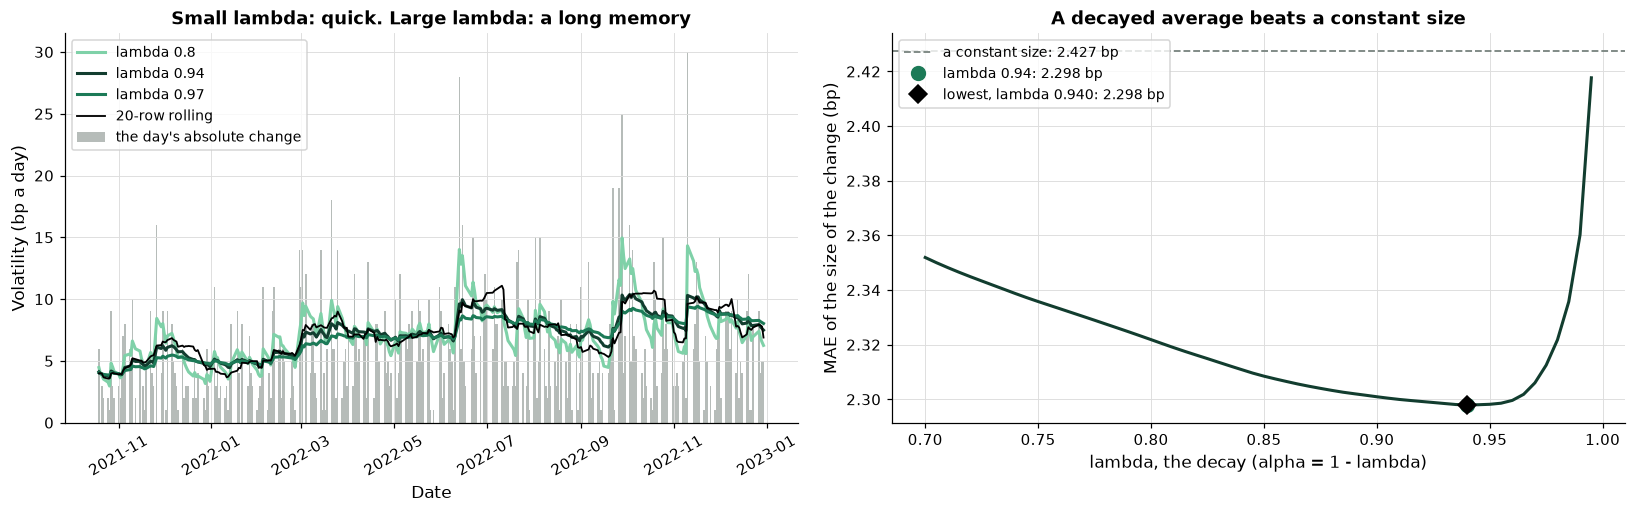

In [40]:
# left: the EWMA volatility of the 10 Yr's changes at three decays, with the 20-row rolling value, over the last 300 development dates
# right: the MAE of the size of the next change against lambda
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 4.8))
shown = volatility.iloc[-300:]
left.bar(shown.index, ten_changes.abs().iloc[-300:], color=plotkit.GREY, alpha=0.55, width=1.0, label="the day's absolute change")
for column, color in zip(shown.columns, [plotkit.GREEN_LIGHT, plotkit.GREEN_DARK, plotkit.GREEN, "black"]):
    left.plot(shown.index, shown[column], color=color, linewidth=2 if column != "20-row rolling" else 1.2, label=f"lambda {column}" if column != "20-row rolling" else "20-row rolling")
left.set_xlabel("Date")
left.set_ylabel("Volatility (bp a day)")
left.set_title("Small lambda: quick. Large lambda: a long memory")
left.tick_params(axis="x", rotation=30)
left.legend(loc="upper left", fontsize=9)
right.plot(mae_by_lambda.index, mae_by_lambda, color=plotkit.GREEN_DARK, linewidth=2)
right.axhline(constant_mae, color=plotkit.GREY, linestyle="--", linewidth=1.2, label=f"a constant size: {constant_mae:.3f} bp")
right.plot([0.94], [mae_by_lambda.loc[0.94]], "o", color=plotkit.GREEN, markersize=9, label=f"lambda 0.94: {mae_by_lambda.loc[0.94]:.3f} bp")
right.plot([mae_by_lambda.idxmin()], [mae_by_lambda.min()], "D", color="black", markersize=8, label=f"lowest, lambda {mae_by_lambda.idxmin():.3f}: {mae_by_lambda.min():.3f} bp")
right.set_xlabel("lambda, the decay (alpha = 1 - lambda)")
right.set_ylabel("MAE of the size of the change (bp)")
right.set_title("A decayed average beats a constant size")
right.legend(loc="upper left", fontsize=9)
fig.tight_layout()
plt.show()

* **Left:** all four lines rise with the big days of the window and fall back; the small lambda follows each spike, and the large lambda keeps the average high for weeks after, like the 20-row rolling value but without its cliff when a day leaves the window. A weight at lambda 0.94 halves in 11.2 rows.
* **Right:** the MAE of the size of a day's change, using the volatility through the row before, is 2.298 bp at lambda 0.94 and 2.427 bp for a constant size: 5.3 percent closer. Lambda 0.94 is also the lowest on this grid (0.70 to 0.995 in steps of 0.005): a fact about these years, and no reason to use it on others. **The size of a change has memory that a smoothing of the squares keeps**, where the level of a change had none: every rule above was further from the level than the last value, and this one is closer to the size than a constant. Day 7's GARCH models that memory.
* This right panel uses the whole development years to show how lambda matters, and the grid of lambdas is a choice made after seeing them. It is a description, not a score: day 7 scores a volatility model walk-forward.

## Excel Side by Side

**The EWMA is one recursive formula in Excel**, and Excel is the quickest place to see what it does. Each formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-21) on the 10 Yr in bp: dates in column A, the level in B, the EWMA in C, the daily change in D (`=B3-B2`), the variance in E, the volatility in F, and a second smoothing in G. The weights sit in H1 (alpha), H2 (lambda), and H3 (a second alpha).

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| The EWMA, first row | `smoothed[0] = values[0]` | `=B2` in C2 | the first level |
| The EWMA, every later row | `alpha * x + (1 - alpha) * previous` | `=$H$1*B3+(1-$H$1)*C2` in C3, filled down | 376.5808 on the last date |
| How long a weight lasts | `np.log(0.5) / np.log(1 - alpha)` | `=LN(0.5)/LN(1-H1)` | 3.1063 rows |
| MAE of simple smoothing, fold 1 | `np.abs(level - value).mean()` | `=SUMPRODUCT(ABS(B506:B757-G505:G756))/ROWS(B506:B757)` | 2.7519 |
| MAE of the last value, fold 1 | `np.abs(level - last).mean()` | `=SUMPRODUCT(ABS(B506:B757-B505:B756))/ROWS(B506:B757)` | 2.7619 |
| The variance, first row, then every later row | `ewma(change ** 2, 1 - lam)` | `=D3^2`, then `=$H$2*E3+(1-$H$2)*D4^2` | volatility 7.4891 bp on the last date |

**The recursion is a column.** Put the first level in C2, write `=$H$1*B3+(1-$H$1)*C2` in C3 with the `$` holding alpha in H1 fixed, and fill down: every row is the weighted average of today's level and yesterday's average, and the EWMA is complete. Change H1 and the whole column redraws, which is the fastest way to feel what alpha does. The one-step value for a date is the cell *above* in the EWMA column, which is why the MAE formula pairs `B506:B757` with `G505:G756`, one row up. On fold 1, alpha 0.9 gives 2.7519 bp against the last value's 2.7619.

**RiskMetrics in two cells.** Start the variance with the first change squared in E3, then write `=$H$2*E3+(1-$H$2)*D4^2` in E4 and fill down, with lambda 0.94 in H2. The square root in column F is the volatility in bp a day: 7.4891 on the last development date. Excel also has a `FORECAST.ETS` function for exponential smoothing, which takes a target date; the course does not use it, because the recursion above scores every date inside the file. A cell formula does not choose alpha by least squares: Solver can search for it, one fold at a time.

Q. Do Excel's values equal Python's?

In [41]:
# Excel's results, from the course's Excel check, beside Python's
excel_side = pd.DataFrame({
    "Excel": [376.58081861203453, 3.1062837195053903, 2.7518844670100426, 2.761904761904762, 7.489121482941084],
    "Python": [tskit.ewma(levels["10 Yr"], 0.2).iloc[-1], np.log(0.5) / np.log(1 - 0.2),
               np.abs(levels["10 Yr"].to_numpy()[splits[0][1]] - tskit.smoothing_values(levels["10 Yr"].to_numpy(), levels["10 Yr"].iloc[0], 0.9)[splits[0][1]]).mean(),
               last_mae["10 Yr"].iloc[0], np.sqrt(tskit.ewma(changes["10 Yr"] ** 2, 0.06).iloc[-1])],
}, index=pd.Index(["EWMA on the last date, alpha 0.2", "rows until a weight halves, alpha 0.2", "MAE of simple smoothing, alpha 0.9, fold 1",
                   "MAE of the last value, fold 1", "RiskMetrics volatility on the last date (bp)"], name="Quantity"))
excel_side["equal within 1e-9"] = (excel_side["Excel"] - excel_side["Python"]).abs() < 1e-9
plotkit.styled(excel_side, [], "Excel beside Python for the 10 Yr: the EWMA, the weights' half-life, the fold-1 scores, and the volatility", fmt="{:.6f}")

,Excel,Python,equal within 1e-9
Quantity,,,
"EWMA on the last date, alpha 0.2",376.580819,376.580819,True
"rows until a weight halves, alpha 0.2",3.106284,3.106284,True
"MAE of simple smoothing, alpha 0.9, fold 1",2.751884,2.751884,True
"MAE of the last value, fold 1",2.761905,2.761905,True
RiskMetrics volatility on the last date (bp),7.489121,7.489121,True


* Every quantity is equal to within 1e-9.

## Save the Day with Git

Today's Git step is undoing a mistake. A tracked results file is overwritten by accident; Git shows exactly what changed and puts the committed version back.

Q. Start a repository in the work folder, and commit the code.

In [42]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [43]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course5b_06_wdcj4fj3 and nowhere else


In [44]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx

Writing .gitignore


In [45]:
!git -C "{work}" add .gitignore mlkit.py tskit.py test_tskit.py
!git -C "{work}" commit -q -m "Day 6: tskit with ewma, smoothing_values, fit_smoothing, and walk_forward_smoothing"
!git -C "{work}" show --stat --format=%s HEAD

Day 6: tskit with ewma, smoothing_values, fit_smoothing, and walk_forward_smoothing

 .gitignore    |   3 +
 mlkit.py      | 568 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 test_tskit.py | 421 +++++++++++++++++++++++++++++++++++++++++++
 tskit.py      | 496 ++++++++++++++++++++++++++++++++++++++++++++++++++
 4 files changed, 1488 insertions(+)


Q. Save the three alphas and commit them.

In [46]:
# the three series' least-squares alphas as a file: 4 decimals and LF line endings
alpha_table[["alpha"]].to_csv("alphas.csv", float_format="%.4f", lineterminator="\n")
print((work / "alphas.csv").read_text(encoding="utf-8"))

series,alpha
10 Yr,0.9426
2s10s,0.9173
IG,0.8947



In [47]:
!git -C "{work}" add alphas.csv
!git -C "{work}" commit -q -m "Day 6: least-squares alphas"

Q. Overwrite the file by mistake. What does Git say changed?

In [48]:
# a mistake: every alpha overwritten with 1.0 (the file is a plain text file, so nothing stops it)
spoiled = alpha_table[["alpha"]].assign(alpha=1.0)
spoiled.to_csv("alphas.csv", float_format="%.4f", lineterminator="\n")

In [49]:
# M marks a tracked file that changed; diff shows the lines: - removed, + added
!git -C "{work}" status --short
!git -C "{work}" diff

 M alphas.csv
?? course3_synthetic_spreads.csv
?? plotkit.py
?? treasury_par_yields.csv


diff --git a/alphas.csv b/alphas.csv
index f972d71..506b287 100644
--- a/alphas.csv
+++ b/alphas.csv
@@ -1,4 +1,4 @@
 series,alpha
-10 Yr,0.9426
-2s10s,0.9173
-IG,0.8947
+10 Yr,1.0000
+2s10s,1.0000
+IG,1.0000


Q. Put the committed version back.

In [50]:
# restore replaces the file with the committed version; the empty status says nothing is left to commit
!git -C "{work}" restore alphas.csv
!git -C "{work}" status --short

?? course3_synthetic_spreads.csv
?? plotkit.py
?? treasury_par_yields.csv


In [51]:
# the file is back as committed
print((work / "alphas.csv").read_text(encoding="utf-8"))

series,alpha
10 Yr,0.9426
2s10s,0.9173
IG,0.8947



* `git restore` threw away the mistake and kept the commit. It only works on a change that was never committed: once a bad file is committed, the way back is another commit. The habit is to commit a good result before an experiment, so the experiment has something to be undone to.

## Bring It Home

Add today's functions to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and activate the course's environment.

```powershell
Set-Location "$HOME\projects\python-fixed-income"
.\.venv\Scripts\Activate.ps1
Set-Location "$HOME\projects\my_bondmath"
```

**Step 2.** Open `tskit.py` and paste the code of today's three `tskit.py` cells (sections 6.1, 6.2, and 6.5) at the end, without their first lines. Do the same for the three `test_tskit.py` cells in `test_tskit.py`. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_tskit.py
```

The last line says `34 passed`.

**Step 4.** Commit.

```powershell
git add tskit.py test_tskit.py
git commit -m "Day 6: tskit with ewma, smoothing_values, fit_smoothing, and walk_forward_smoothing"
```

## You Can Now

* Build an EWMA as one recursive formula, in Python and in Excel, and say what alpha does to the weights.
* Say that simple smoothing is the EWMA with a least-squares alpha, and read the sum of squared misses against alpha.
* Say what Holt's trend and the damped trend add, and read alpha and beta on a heatmap.
* Read every setting of `ExponentialSmoothing`, and sweep the initialisation and a fixed alpha.
* Score a smoothing walk-forward (`walk_forward_smoothing`) against the last value, the drift, and an AR(1), and read the gap against how far the folds differ.
* Say plainly what was found: no smoother beat the last value on the 10 Yr, the 2s10s, or the invented IG spread (MASE from 1.0003 to 1.0072), and the EWMA of squared changes, with RiskMetrics' lambda of 0.94, describes the size of a change better than a constant.

Next, week 2, day 2: volatility clustering and GARCH, a model of the size of a change, scored walk-forward.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the five series, makes day 2's five folds (`splits`, `last_mae`, and the changes with their folds `changes`, `change_splits`), and defines `check`, a small function that marks your answers.

In [52]:
# the Treasury curve (percent) and the course's synthetic spreads (bp): one row per date, the same dates in both files
treasury = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"]).set_index("date")
spreads = pd.read_csv("course3_synthetic_spreads.csv", parse_dates=["date"]).set_index("date")
print(f"Treasury file: {len(treasury):,} dates; spread file: {len(spreads):,} dates; same dates: {treasury.index.equals(spreads.index)}")

# the development and held-out years, set now, before any model is fitted
DEVELOPMENT_END = "2022-12-30"
development = treasury.loc[:DEVELOPMENT_END]
dev_spreads = spreads.loc[:DEVELOPMENT_END]
held_out_dates = treasury.index[treasury.index > DEVELOPMENT_END]
print(f"development years: {len(development):,} dates, {development.index[0].date()} to {development.index[-1].date()}")
print(f"held-out years: {len(held_out_dates):,} dates, {held_out_dates[0].date()} to {held_out_dates[-1].date()}, not opened until the capstone")

# five series, all in bp: yields times 100 (rounded to the file's two decimals of a percent), spreads as they are
levels = pd.DataFrame({
    "2 Yr": (development["2 Yr"] * 100).round(2),
    "10 Yr": (development["10 Yr"] * 100).round(2),
    "2s10s": ((development["10 Yr"] - development["2 Yr"]) * 100).round(2),
    "IG": dev_spreads["ig_spread_bp"],
    "HY": dev_spreads["hy_spread_bp"],
})
# nothing below reads a held-out row: drop the full tables
del treasury, spreads, development, dev_spreads
print(f"five series in bp: {list(levels.columns)}; blank cells: {int(levels.isna().sum().sum())}")

# the walk-forward windows of section 2.5, used by every later day: fit on 504 dates first, then score 252 at a time
MIN_TRAIN, TEST_SIZE = 504, 252
# day 2's five folds on the levels: fit on 504 dates first, then score 252 at a time
splits = mlkit.walk_forward_splits(levels.index, min_train=MIN_TRAIN, test_size=TEST_SIZE)
for number, (train, test) in enumerate(splits, start=1):
    mlkit.assert_past_only(levels.index[train], levels.index[test])
    print(f"fold {number}: fit on {len(train)} dates to {levels.index[train[-1]].date()}, "
          f"score {len(test)} from {levels.index[test[0]].date()} to {levels.index[test[-1]].date()}")

# the last value carried forward: each date's miss is its level less the level on the row before (day 2's baseline)
last_mae = pd.DataFrame({column: [np.abs(levels[column].iloc[test].to_numpy() - levels[column].iloc[test - 1].to_numpy()).mean()
                                  for _, test in splits] for column in levels.columns},
                        index=pd.Index(range(1, len(splits) + 1), name="fold"))
print(last_mae.mean().round(4).to_string())

# day 5's folds for the changes (one row later) are only needed to score its AR(1) beside the smoothers
changes = levels.diff().dropna()
change_splits = [(train[1:] - 1, test - 1) for train, test in splits]


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

Treasury file: 2,940 dates; spread file: 2,940 dates; same dates: True
development years: 2,001 dates, 2015-01-02 to 2022-12-30
held-out years: 939 dates, 2023-01-03 to 2026-10-02, not opened until the capstone
five series in bp: ['2 Yr', '10 Yr', '2s10s', 'IG', 'HY']; blank cells: 0
fold 1: fit on 504 dates to 2017-01-05, score 252 from 2017-01-06 to 2018-01-08
fold 2: fit on 756 dates to 2018-01-08, score 252 from 2018-01-09 to 2019-01-11
fold 3: fit on 1008 dates to 2019-01-11, score 252 from 2019-01-14 to 2020-01-15
fold 4: fit on 1260 dates to 2020-01-15, score 252 from 2020-01-16 to 2021-01-19
fold 5: fit on 1512 dates to 2021-01-19, score 252 from 2021-01-20 to 2022-01-19
2 Yr     2.1881
10 Yr    3.1937
2s10s    2.1548
IG       0.8017
HY       3.5018


### Exercise 1

Q. Fit simple smoothing by least squares to the invented IG spread's first training window (`levels["IG"].iloc[splits[0][0]]`) with `tskit.fit_smoothing`, and store its alpha in **ex1_alpha**. Is it nearer 0 or nearer 1?

In [53]:
ex1_alpha = ...

In [54]:
check("Exercise 1 alpha, IG", ex1_alpha, 0.894729750290975)

Exercise 1 alpha, IG: not attempted yet


### Exercise 2

Q. Score simple smoothing on the invented HY spread's levels, walk-forward on the five folds (`tskit.walk_forward_smoothing(levels["HY"], splits)`), and store its MASE against the last value (its five-fold average MAE over `last_mae["HY"].mean()`) in **ex2_mase**. Is it above or below 1?

In [55]:
ex2_mase = ...

In [56]:
check("Exercise 2 MASE of simple smoothing, HY", ex2_mase, 1.0032580049975919)

Exercise 2 MASE of simple smoothing, HY: not attempted yet


### Exercise 3

Q. Add a function to your module. `weight_half_life(alpha)` returns the number of rows after which an EWMA's weight has halved, `ln(0.5) / ln(1 - alpha)`. It refuses an alpha that is not strictly between 0 and 1 with `ValueError`. Write the docstring first. Add `test_weight_half_life`, which checks that alpha 0.5 gives 1 row, that the weight at that many rows back is half the newest row's, and the refusals. Run pytest, reload the module, and store the half-life of RiskMetrics' lambda of 0.94 (alpha 0.06) in **ex3_rows**.

Write the function in the cell that starts with `%%writefile -a tskit.py` and the test in the one that starts with `%%writefile -a test_tskit.py`, and run each of those cells once.

In [57]:
%%writefile -a tskit.py


# Exercise 3: write weight_half_life(alpha) below this line

Appending to tskit.py


In [58]:
%%writefile -a test_tskit.py


# Exercise 3: write test_weight_half_life() below this line

Appending to test_tskit.py


In [59]:
# run pytest, reload the module, then use your function for alpha = 0.06
ex3_rows = ...

In [60]:
check("Exercise 3 half-life of lambda 0.94, rows", ex3_rows, 11.202305583621158)

Exercise 3 half-life of lambda 0.94, rows: not attempted yet


### Exercise 4

Q. What is the RiskMetrics volatility (lambda 0.94) of the 2 Yr's daily change on the last development date, in bp? Use `tskit.ewma` on the squared changes with alpha 0.06 and take the square root of the last value. Store it in **ex4_vol**.

In [61]:
ex4_vol = ...

In [62]:
check("Exercise 4 volatility of the 2 Yr, bp", ex4_vol, 6.821058345552518)

Exercise 4 volatility of the 2 Yr, bp: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that returns an exponentially weighted average to use as the value for each date, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
The exponentially weighted average of a series of levels, used as the value for each date.

    levels is a dated Series of levels in bp. alpha is the weight on the newest row.
    Returns a Series on the same dates whose entry for a date is built only from the rows before that date
    (the first date has no value), so it can be scored against that date's level.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns a Series, and contains one bug.

In [63]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def smoothed_value(levels, alpha=0.5):
    """The exponentially weighted average of a series of levels, used as the value for each date.

    levels is a dated Series of levels in bp. alpha is the weight on the newest row.
    Returns a Series on the same dates whose entry for a date is built only from the rows before that date
    (the first date has no value), so it can be scored against that date's level.
    """
    # alpha = 1 - lambda: pandas' ewm with adjust=False is the recursion s[t] = alpha x[t] + (1 - alpha) s[t-1]
    return levels.ewm(alpha=alpha, adjust=False).mean()

Q. Before you run the next cell: a series that wanders by a few bp a day, smoothed with alpha 0.5. How far should the smoothed value be from the level it is the value for, on average? Compare the function's average miss with the typical daily change.

In [64]:
rng = np.random.default_rng(SEED)
series = pd.Series(100 + rng.normal(0, 2, 300).cumsum(), index=pd.bdate_range("2020-01-01", periods=300))
miss = (series - smoothed_value(series)).abs().mean()
print(f"typical daily change {series.diff().abs().mean():.2f} bp; the function's average miss {miss:.2f} bp")

typical daily change 1.47 bp; the function's average miss 0.86 bp


Q. Test the function against its docstring before you trust it.

In [65]:
# the test, written from the docstring before the code is trusted
rng = np.random.default_rng(SEED)
series = pd.Series(100 + rng.normal(0, 2, 300).cumsum(), index=pd.bdate_range("2020-01-01", periods=300))
bumped = series.copy()
bumped.iloc[200] += 50.0
# the value for a date may not move when that date's own level moves
before, after = smoothed_value(series).iloc[200], smoothed_value(bumped).iloc[200]
assert before == after, f"the value for {series.index[200].date()} moved from {before:.2f} to {after:.2f} when that date's own level moved: it uses the date it is scored on"
print("the value for a date does not use that date's level")

AssertionError: the value for 2020-10-07 moved from 88.28 to 113.28 when that date's own level moved: it uses the date it is scored on

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the fixed function's average miss on the test series in **ex5_miss**.

In [66]:
# fix the function above and run the test again, then store the answer
ex5_miss = ...

In [67]:
check("Exercise 5 average miss of the fixed function", ex5_miss, 1.7251689982800533)

Exercise 5 average miss of the fixed function: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```